# Dataset Acquisition & Verification

##### P-00 || GPU CUDA CHECK

In [1]:
import torch
import torchvision
import torchaudio

print("=" * 60)
print("ENVIRONMENT CHECK — GPU / CUDA")
print("=" * 60)

print(f"PyTorch version:      {torch.__version__}")
print(f"Torchvision version:  {torchvision.__version__}")
print(f"Torchaudio version:   {torchaudio.__version__}")
print(f"CUDA available:       {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"CUDA build version:   {torch.version.cuda}")
    print(f"Device count:         {torch.cuda.device_count()}")
    print(f"Device name:          {torch.cuda.get_device_name(0)}")
    print(f"Compute capability:   {torch.cuda.get_device_capability(0)}")
    print(f"Supported archs:      {torch.cuda.get_arch_list()}")

    print("\nRunning a matrix multiply on GPU to confirm real compute works")
    print("(is_available() can be True even without a working kernel for this arch)...")
    try:
        a = torch.randn(2048, 2048, device="cuda")
        b = torch.randn(2048, 2048, device="cuda")
        c = a @ b
        torch.cuda.synchronize()
        print(f"SUCCESS — result shape: {tuple(c.shape)}, device: {c.device}")
        print("GPU compute confirmed working.")
    except RuntimeError as e:
        print("FAILED — GPU was detected but compute failed.")
        print("This usually means the installed PyTorch build has no compiled")
        print("kernel for this GPU's architecture (sm_120 / Blackwell).")
        print("Fix: reinstall PyTorch from the cu128 index:")
        print('  pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu128')
        print(f"\nError detail: {e}")
else:
    print("CUDA not available.")
    print("Check: (1) NVIDIA driver is installed and up to date,")
    print("       (2) PyTorch was installed via the cu128 index, not conda default.")

print("=" * 60)

ENVIRONMENT CHECK — GPU / CUDA
PyTorch version:      2.11.0+cu128
Torchvision version:  0.26.0+cu128
Torchaudio version:   2.11.0+cu128
CUDA available:       True
CUDA build version:   12.8
Device count:         1
Device name:          NVIDIA GeForce RTX 5060 Ti
Compute capability:   (12, 0)
Supported archs:      ['sm_75', 'sm_80', 'sm_86', 'sm_90', 'sm_100', 'sm_120']

Running a matrix multiply on GPU to confirm real compute works
(is_available() can be True even without a working kernel for this arch)...
SUCCESS — result shape: (2048, 2048), device: cuda:0
GPU compute confirmed working.


##### P-01 || Dataset Verification

In [2]:
"""
01_dataset_verification.txt
One-time diagnostic — HAM10000 dataset verification for Phase 1 (P2).

Checks (run as a full set; every failure is collected and reported together,
not stopped at the first one):
  1. Metadata row count vs. expected image count
  2. Image count on disk vs. expected image count
  3. image_id cross-reference: metadata <-> disk (missing / extra)
  4. Corrupted image files (PIL.Image.verify())
  5. Required metadata columns present

Null counts for age/sex/localization are reported as INFORMATIONAL, not
treated as failures — HAM10000 is known to contain some missing age values,
and Section 4.3 of the methodology explicitly handles missing age via a
continuous field + missing-flag, so this is expected data, not corruption.
"""

from pathlib import Path
import pandas as pd
from PIL import Image

# --- Paths ---
BASE_DIR = Path(r"T:\Thesis - Development")
IMAGES_DIR = BASE_DIR / "Resources" / "Dataset" / "HAM10000" / "images"
METADATA_PATH = BASE_DIR / "Resources" / "Dataset" / "HAM10000" / "HAM10000_metadata.tab"
ARTIFACTS_DIR = BASE_DIR / "Resources" / "Artifacts" / "Phase 1 - P2"
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)
REPORT_PATH = ARTIFACTS_DIR / "dataset_verification_report.txt"

EXPECTED_COUNT = 10015
REQUIRED_COLUMNS = {"lesion_id", "image_id", "dx", "dx_type", "age", "sex", "localization"}
VALID_EXTENSIONS = (".jpg", ".jpeg", ".png")

report_lines = []
def log(line=""):
    print(line)
    report_lines.append(line)

failures = []

log("=" * 60)
log("HAM10000 DATASET VERIFICATION — Phase 1 P2")
log("=" * 60)

# --- Sanity: paths exist ---
if not IMAGES_DIR.exists():
    raise FileNotFoundError(f"Images directory not found: {IMAGES_DIR}")
if not METADATA_PATH.exists():
    raise FileNotFoundError(f"Metadata file not found: {METADATA_PATH}")

# --- 1. Load metadata ---
metadata = pd.read_csv(METADATA_PATH, sep="\t")
log(f"\nMetadata rows: {len(metadata)}")
if len(metadata) != EXPECTED_COUNT:
    failures.append(f"Metadata row count mismatch: expected {EXPECTED_COUNT}, got {len(metadata)}")

# --- 2. Required columns present ---
missing_columns = REQUIRED_COLUMNS - set(metadata.columns)
if missing_columns:
    failures.append(f"Missing required metadata columns: {sorted(missing_columns)}")
else:
    log("All required metadata columns present: " + ", ".join(sorted(REQUIRED_COLUMNS)))

# --- 3. Images on disk ---
image_files = [f for f in IMAGES_DIR.iterdir() if f.suffix.lower() in VALID_EXTENSIONS]
disk_ids = {f.stem for f in image_files}
log(f"\nImages on disk: {len(image_files)}")
if len(image_files) != EXPECTED_COUNT:
    failures.append(f"Image count on disk mismatch: expected {EXPECTED_COUNT}, got {len(image_files)}")

# --- 4. image_id cross-reference ---
if "image_id" in metadata.columns:
    metadata_ids = set(metadata["image_id"])
    missing_on_disk = metadata_ids - disk_ids
    extra_on_disk = disk_ids - metadata_ids

    if missing_on_disk:
        sample = list(missing_on_disk)[:5]
        failures.append(f"{len(missing_on_disk)} image_id(s) in metadata but missing on disk. Sample: {sample}")
    if extra_on_disk:
        sample = list(extra_on_disk)[:5]
        failures.append(f"{len(extra_on_disk)} image file(s) on disk not referenced in metadata. Sample: {sample}")
    if not missing_on_disk and not extra_on_disk:
        log("image_id cross-reference: exact match, 0 missing, 0 extra.")

# --- 5. Corrupted file check ---
log(f"\nChecking {len(image_files)} images for corruption (PIL.Image.verify())...")
corrupted = []
for f in image_files:
    try:
        with Image.open(f) as img:
            img.verify()
    except Exception as e:
        corrupted.append((f.name, str(e)))

if corrupted:
    failures.append(f"{len(corrupted)} corrupted image file(s). Sample: {corrupted[:5]}")
else:
    log("0 corrupted files.")

# --- Informational: null counts (NOT treated as failures) ---
log("\n--- Informational: field population (age missing is expected, handled in Section 4.3) ---")
for col in ("age", "sex", "localization"):
    if col in metadata.columns:
        null_count = metadata[col].isna().sum()
        log(f"  {col}: {null_count} null / {len(metadata)} total ({null_count / len(metadata):.2%})")

# --- Final verdict ---
log("\n" + "=" * 60)
if failures:
    log(f"VERIFICATION FAILED — {len(failures)} issue(s) found:")
    for i, f in enumerate(failures, 1):
        log(f"  {i}. {f}")
else:
    log("VERIFICATION PASSED — all hard checks succeeded.")
log("=" * 60)

# --- Write report to disk ---
REPORT_PATH.write_text("\n".join(report_lines), encoding="utf-8")
print(f"\nReport written to: {REPORT_PATH}")

if failures:
    raise AssertionError(f"Dataset verification failed with {len(failures)} issue(s) — see report above.")

HAM10000 DATASET VERIFICATION — Phase 1 P2

Metadata rows: 10015
All required metadata columns present: age, dx, dx_type, image_id, lesion_id, localization, sex

Images on disk: 10015
image_id cross-reference: exact match, 0 missing, 0 extra.

Checking 10015 images for corruption (PIL.Image.verify())...
0 corrupted files.

--- Informational: field population (age missing is expected, handled in Section 4.3) ---
  age: 57 null / 10015 total (0.57%)
  sex: 0 null / 10015 total (0.00%)
  localization: 0 null / 10015 total (0.00%)

VERIFICATION PASSED — all hard checks succeeded.

Report written to: T:\Thesis - Development\Resources\Artifacts\Phase 1 - P2\dataset_verification_report.txt


##### P-02 || Descriptive Statistics

In [3]:
"""
02_descriptive_statistics.txt
One-time diagnostic — HAM10000 descriptive statistics for Phase 1 (P2).

Produces:
  - dx_value_counts.csv            (diagnosis class distribution — the 7 target classes)
  - sex_value_counts.csv
  - localization_value_counts.csv  (anatomical site distribution)
  - age_value_counts.csv           (age is recorded in discrete 5-year steps in HAM10000,
                                     so a value-count table is meaningful, not one row per float)
  - age_summary_stats.csv          (mean/median/std/min/max/null count)

Also prints the NV:DF class-imbalance ratio to console — the headline
imbalance figure the class-balanced loss (Section 3.4) is built around.
"""

from pathlib import Path
import pandas as pd

# --- Paths ---
BASE_DIR = Path(r"T:\Thesis - Development")
METADATA_PATH = BASE_DIR / "Resources" / "Dataset" / "HAM10000" / "HAM10000_metadata.tab"
ARTIFACTS_DIR = BASE_DIR / "Resources" / "Artifacts" / "Phase 1 - P2"
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

metadata = pd.read_csv(METADATA_PATH, sep="\t")

print("=" * 60)
print("HAM10000 DESCRIPTIVE STATISTICS — Phase 1 P2")
print("=" * 60)


def write_value_counts(column: str, filename: str):
    """Value counts + percentage of total, sorted descending, written to CSV."""
    counts = metadata[column].value_counts(dropna=False)
    pct = (counts / len(metadata) * 100).round(2)
    table = pd.DataFrame({column: counts.index, "count": counts.values, "percent": pct.values})
    out_path = ARTIFACTS_DIR / filename
    table.to_csv(out_path, index=False)
    print(f"\n{column} — written to {filename}")
    print(table.to_string(index=False))
    return table


# --- Categorical distributions ---
dx_table = write_value_counts("dx", "dx_value_counts.csv")
write_value_counts("sex", "sex_value_counts.csv")
write_value_counts("localization", "localization_value_counts.csv")

# --- Age: discrete value counts ---
age_table = write_value_counts("age", "age_value_counts.csv")

# --- Age: summary statistics ---
age_summary = metadata["age"].describe()
age_summary_df = pd.DataFrame({
    "statistic": ["count", "mean", "std", "min", "25%", "50% (median)", "75%", "max", "null_count"],
    "value": [
        age_summary["count"], round(age_summary["mean"], 2), round(age_summary["std"], 2),
        age_summary["min"], age_summary["25%"], age_summary["50%"], age_summary["75%"],
        age_summary["max"], metadata["age"].isna().sum(),
    ],
})
age_summary_path = ARTIFACTS_DIR / "age_summary_stats.csv"
age_summary_df.to_csv(age_summary_path, index=False)
print(f"\nage summary statistics — written to age_summary_stats.csv")
print(age_summary_df.to_string(index=False))

# --- NV:DF imbalance ratio (headline figure) ---
nv_count = (metadata["dx"] == "nv").sum()
df_count = (metadata["dx"] == "df").sum()
ratio = nv_count / df_count
print("\n" + "=" * 60)
print(f"NV:DF class imbalance ratio — {nv_count} : {df_count} = {ratio:.1f}:1")
print("=" * 60)

print(f"\nAll CSVs written to: {ARTIFACTS_DIR}")

HAM10000 DESCRIPTIVE STATISTICS — Phase 1 P2

dx — written to dx_value_counts.csv
   dx  count  percent
   nv   6705    66.95
  mel   1113    11.11
  bkl   1099    10.97
  bcc    514     5.13
akiec    327     3.27
 vasc    142     1.42
   df    115     1.15

sex — written to sex_value_counts.csv
    sex  count  percent
   male   5406    53.98
 female   4552    45.45
unknown     57     0.57

localization — written to localization_value_counts.csv
   localization  count  percent
           back   2192    21.89
lower extremity   2077    20.74
          trunk   1404    14.02
upper extremity   1118    11.16
        abdomen   1022    10.20
           face    745     7.44
          chest    407     4.06
           foot    319     3.19
        unknown    234     2.34
           neck    168     1.68
          scalp    128     1.28
           hand     90     0.90
            ear     56     0.56
        genital     48     0.48
          acral      7     0.07

age — written to age_value_counts.csv

##### P-03 || Image Quality Profiling

In [4]:
"""
03_image_quality_profiling.txt
One-time diagnostic — HAM10000 image quality profiling for Phase 1 (P2).

For every image, computes:
  - brightness        (mean pixel intensity, grayscale)
  - contrast           (std dev, grayscale)
  - blur_laplacian_var  (variance of the Laplacian — standard sharpness measure;
                          lower values indicate a blurrier image)
  - mean_b, mean_g, mean_r (per-channel means, original color image)

Produces:
  - image_quality_profile.csv   (one row per image: image_id, dx, all metrics)
  - image_quality_summary.csv   (aggregate mean/std/min/max across the dataset)

PROFILING ONLY — no image is excluded on the basis of these numbers. This is
stated explicitly here and must also be stated explicitly in the methodology
write-up (per Phase-1_Updated.md).
"""

from pathlib import Path
import cv2
import numpy as np
import pandas as pd
from tqdm import tqdm

# --- Paths ---
BASE_DIR = Path(r"T:\Thesis - Development")
IMAGES_DIR = BASE_DIR / "Resources" / "Dataset" / "HAM10000" / "images"
METADATA_PATH = BASE_DIR / "Resources" / "Dataset" / "HAM10000" / "HAM10000_metadata.tab"
ARTIFACTS_DIR = BASE_DIR / "Resources" / "Artifacts" / "Phase 1 - P2"
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

VALID_EXTENSIONS = (".jpg", ".jpeg", ".png")

metadata = pd.read_csv(METADATA_PATH, sep="\t")
dx_lookup = dict(zip(metadata["image_id"], metadata["dx"]))

image_files = sorted(f for f in IMAGES_DIR.iterdir() if f.suffix.lower() in VALID_EXTENSIONS)
print("=" * 60)
print("HAM10000 IMAGE QUALITY PROFILING — Phase 1 P2")
print("=" * 60)
print(f"Profiling {len(image_files)} images (no exclusions will be made)...\n")

rows = []
for f in tqdm(image_files, desc="Profiling images"):
    image_id = f.stem
    img_bgr = cv2.imread(str(f), cv2.IMREAD_COLOR)

    if img_bgr is None:
        rows.append({
            "image_id": image_id, "dx": dx_lookup.get(image_id),
            "brightness": np.nan, "contrast": np.nan, "blur_laplacian_var": np.nan,
            "mean_b": np.nan, "mean_g": np.nan, "mean_r": np.nan,
        })
        continue

    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    brightness = float(np.mean(gray))
    contrast = float(np.std(gray))
    blur_var = float(cv2.Laplacian(gray, cv2.CV_64F).var())
    mean_b, mean_g, mean_r = [float(x) for x in cv2.mean(img_bgr)[:3]]

    rows.append({
        "image_id": image_id, "dx": dx_lookup.get(image_id),
        "brightness": brightness, "contrast": contrast, "blur_laplacian_var": blur_var,
        "mean_b": mean_b, "mean_g": mean_g, "mean_r": mean_r,
    })

profile_df = pd.DataFrame(rows)
profile_path = ARTIFACTS_DIR / "image_quality_profile.csv"
profile_df.to_csv(profile_path, index=False)
print(f"\nPer-image profile written to: {profile_path}")

# --- Aggregate summary ---
metric_cols = ["brightness", "contrast", "blur_laplacian_var", "mean_b", "mean_g", "mean_r"]
summary_df = profile_df[metric_cols].agg(["mean", "std", "min", "max"]).round(2).reset_index()
summary_df = summary_df.rename(columns={"index": "statistic"})
summary_path = ARTIFACTS_DIR / "image_quality_summary.csv"
summary_df.to_csv(summary_path, index=False)

print(f"Aggregate summary written to: {summary_path}\n")
print(summary_df.to_string(index=False))

failed = profile_df["brightness"].isna().sum()
if failed:
    print(f"\nNOTE: {failed} image(s) failed to load via cv2.imread — check these separately.")
else:
    print(f"\nAll {len(profile_df)} images profiled successfully.")

print("=" * 60)

HAM10000 IMAGE QUALITY PROFILING — Phase 1 P2
Profiling 10015 images (no exclusions will be made)...



Profiling images: 100%|██████████| 10015/10015 [01:52<00:00, 88.75it/s]



Per-image profile written to: T:\Thesis - Development\Resources\Artifacts\Phase 1 - P2\image_quality_profile.csv
Aggregate summary written to: T:\Thesis - Development\Resources\Artifacts\Phase 1 - P2\image_quality_summary.csv

statistic  brightness  contrast  blur_laplacian_var  mean_b  mean_g  mean_r
     mean      156.56     28.04               79.23  145.49  139.26  194.70
      std       19.23     11.36              124.97   24.24   21.86   25.06
      min       58.22      5.26                7.62   55.46   52.03   63.05
      max      229.89     85.49             3825.02  238.21  224.03  254.29

All 10015 images profiled successfully.


##### P-04 || Mask Coverage Verification

In [5]:
"""
04_mask_coverage_verification.txt
One-time diagnostic — HAM10000 segmentation mask verification for Phase 1 (P2).

Uses the CORRECTED mask source: HAM10000_segmentations_lesion_tschandl
(Harvard Dataverse, Tschandl's team) — NOT ISIC 2018 Task 1, which was
confirmed in the P1 attempt to have 0% image_id overlap with HAM10000.

Checks:
  1. Filters __MACOSX / "._"-prefixed AppleDouble junk from the extracted zip
  2. Extracts image_id from each mask filename
  3. Cross-references mask coverage against HAM10000 metadata, PER CLASS
     (not just one aggregate number)
  4. Checks the reverse direction — "orphan" masks whose image_id doesn't
     exist in HAM10000 metadata at all
  5. Confirms every mask file is readable and genuinely binary (only 0/255
     pixel values) — a cheap check now vs. a mysterious bug in Phase 4

Hard failures (raised at the end): unreadable/corrupted mask files, orphan
masks, filenames that don't parse. Non-binary pixel values are reported as
informational, not a hard failure, since some tools export near-binary
masks with light anti-aliasing at edges.

REMINDER: the methodology currently states these masks are "the same ones
used by Javaid and Gamage" — that claim was written under the old (wrong)
ISIC 2018 Task 1 assumption and is now UNVERIFIED. Check it against those
two papers directly before it goes into the write-up.
"""

import re
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
from tqdm import tqdm

# --- Paths ---
BASE_DIR = Path(r"T:\Thesis - Development")
METADATA_PATH = BASE_DIR / "Resources" / "Dataset" / "HAM10000" / "HAM10000_metadata.tab"
MASKS_DIR = BASE_DIR / "Resources" / "Dataset" / "HAM10000_Tschandl_Segmentations" / "HAM10000_segmentations_lesion_tschandl"
ARTIFACTS_DIR = BASE_DIR / "Resources" / "Artifacts" / "Phase 1 - P2"
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

report_lines = []
def log(line=""):
    print(line)
    report_lines.append(line)

failures = []

log("=" * 60)
log("HAM10000 MASK COVERAGE VERIFICATION — Phase 1 P2")
log("Mask source: HAM10000_segmentations_lesion_tschandl (corrected)")
log("=" * 60)

if not MASKS_DIR.exists():
    raise FileNotFoundError(f"Masks directory not found: {MASKS_DIR}")
if not METADATA_PATH.exists():
    raise FileNotFoundError(f"Metadata file not found: {METADATA_PATH}")

metadata = pd.read_csv(METADATA_PATH, sep="\t")

# --- 1. List mask files, filtering junk ---
all_files = list(MASKS_DIR.iterdir())
mask_files = [
    f for f in all_files
    if f.suffix.lower() == ".png"
    and "__MACOSX" not in f.parts
    and not f.name.startswith("._")
]
log(f"\nTotal files found: {len(all_files)}")
log(f"Mask files after filtering junk (__MACOSX, ._*): {len(mask_files)}")

# --- 2. Parse image_id from each mask filename ---
id_pattern = re.compile(r"(ISIC_\d+)")
mask_id_to_path = {}
unparsed = []
for f in mask_files:
    match = id_pattern.match(f.stem)
    if match:
        mask_id_to_path[match.group(1)] = f
    else:
        unparsed.append(f.name)

if unparsed:
    failures.append(f"{len(unparsed)} mask filename(s) did not parse to an ISIC image_id. Sample: {unparsed[:5]}")

mask_ids = set(mask_id_to_path.keys())
log(f"Successfully parsed mask image_ids: {len(mask_ids)}")

# --- 3. Per-class coverage ---
log("\n--- Per-class mask coverage ---")
coverage_rows = []
for dx_class in sorted(metadata["dx"].unique()):
    class_ids = set(metadata.loc[metadata["dx"] == dx_class, "image_id"])
    covered = class_ids & mask_ids
    missing = class_ids - mask_ids
    coverage_pct = round(len(covered) / len(class_ids) * 100, 2) if class_ids else 0.0
    coverage_rows.append({
        "dx": dx_class,
        "total_images": len(class_ids),
        "with_mask": len(covered),
        "coverage_pct": coverage_pct,
        "missing_count": len(missing),
        "missing_sample": list(missing)[:5],
    })

coverage_df = pd.DataFrame(coverage_rows)
log(coverage_df.drop(columns=["missing_sample"]).to_string(index=False))

overall_missing = coverage_df["missing_count"].sum()
if overall_missing > 0:
    failures.append(f"{overall_missing} HAM10000 image(s) missing a mask across all classes — see per-class table.")

coverage_path = ARTIFACTS_DIR / "mask_coverage_per_class.csv"
coverage_df.to_csv(coverage_path, index=False)
log(f"\nPer-class coverage written to: {coverage_path}")

# --- 4. Orphan masks (mask exists, but image_id not in metadata) ---
metadata_ids = set(metadata["image_id"])
orphan_ids = mask_ids - metadata_ids
if orphan_ids:
    failures.append(f"{len(orphan_ids)} orphan mask(s) — image_id not found in HAM10000 metadata. Sample: {list(orphan_ids)[:5]}")
else:
    log("\nNo orphan masks — every mask's image_id exists in HAM10000 metadata.")

# --- 5. Mask file readability + binary check ---
log(f"\nChecking {len(mask_files)} mask files are readable and binary...")
unreadable = []
non_binary = []
for image_id, path in tqdm(mask_id_to_path.items(), desc="Checking masks"):
    mask = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if mask is None:
        unreadable.append(path.name)
        continue
    unique_vals = np.unique(mask)
    if not np.all(np.isin(unique_vals, [0, 255])):
        non_binary.append((path.name, unique_vals.tolist()[:10]))

if unreadable:
    failures.append(f"{len(unreadable)} mask file(s) failed to load. Sample: {unreadable[:5]}")
else:
    log("All mask files loaded successfully.")

if non_binary:
    log(f"\nINFORMATIONAL: {len(non_binary)} mask(s) contain non-binary pixel values (not just 0/255).")
    log(f"  Sample: {non_binary[:5]}")
else:
    log("All masks confirmed genuinely binary (0/255 only).")

# --- Final verdict ---
log("\n" + "=" * 60)
if failures:
    log(f"VERIFICATION FAILED — {len(failures)} issue(s) found:")
    for i, f in enumerate(failures, 1):
        log(f"  {i}. {f}")
else:
    log("VERIFICATION PASSED — all hard checks succeeded.")
log("=" * 60)
log("\nREMINDER: 'same masks as Javaid/Gamage' claim is UNVERIFIED under the")
log("corrected Tschandl source — check against both papers before write-up.")

report_path = ARTIFACTS_DIR / "mask_coverage_verification_report.txt"
report_path.write_text("\n".join(report_lines), encoding="utf-8")
print(f"\nReport written to: {report_path}")

if failures:
    raise AssertionError(f"Mask verification failed with {len(failures)} issue(s) — see report above.")

HAM10000 MASK COVERAGE VERIFICATION — Phase 1 P2
Mask source: HAM10000_segmentations_lesion_tschandl (corrected)

Total files found: 10015
Mask files after filtering junk (__MACOSX, ._*): 10015
Successfully parsed mask image_ids: 10015

--- Per-class mask coverage ---
   dx  total_images  with_mask  coverage_pct  missing_count
akiec           327        327         100.0              0
  bcc           514        514         100.0              0
  bkl          1099       1099         100.0              0
   df           115        115         100.0              0
  mel          1113       1113         100.0              0
   nv          6705       6705         100.0              0
 vasc           142        142         100.0              0

Per-class coverage written to: T:\Thesis - Development\Resources\Artifacts\Phase 1 - P2\mask_coverage_per_class.csv

No orphan masks — every mask's image_id exists in HAM10000 metadata.

Checking 10015 mask files are readable and binary...


Checking masks: 100%|██████████| 10015/10015 [01:58<00:00, 84.59it/s]

All mask files loaded successfully.
All masks confirmed genuinely binary (0/255 only).

VERIFICATION PASSED — all hard checks succeeded.

REMINDER: 'same masks as Javaid/Gamage' claim is UNVERIFIED under the
corrected Tschandl source — check against both papers before write-up.

Report written to: T:\Thesis - Development\Resources\Artifacts\Phase 1 - P2\mask_coverage_verification_report.txt


# Preprocessing Pipeline

##### Hair Detection & Removal


In [1]:
"""
05_00_hair_config.txt
Hair removal — configuration (Phase 1, P2, Section 5).

All tunable parameters live here. Every function file after this one
references these variables rather than hardcoding values, so a parameter
change during validation only needs to happen in one place.
"""

from pathlib import Path

# --- Paths ---
BASE_DIR = Path(r"T:\Thesis - Development")
DATASET_DIR = BASE_DIR / "Resources" / "Dataset"
IMAGES_DIR = DATASET_DIR / "HAM10000" / "images"
MASKS_DIR = DATASET_DIR / "HAM10000_Tschandl_Segmentations" / "HAM10000_segmentations_lesion_tschandl"
ARTIFACTS_DIR = BASE_DIR / "Resources" / "Artifacts" / "Phase 1 - P2"
HAIR_MASKS_DIR = ARTIFACTS_DIR / "HairMasks"
HAIR_MASKS_DIR.mkdir(parents=True, exist_ok=True)

# --- Multi-scale BlackHat ---
# Two kernel sizes: smaller catches thin hairs, larger catches thick hairs.
# Responses are fused by pixel-wise max.
BLACKHAT_KERNEL_SIZES = (9, 17)

# --- Pre-threshold blur ---
# Suppresses speckle noise in the BlackHat response before thresholding.
GAUSSIAN_BLUR_KSIZE = (3, 3)

# --- Dual thresholding ---
# Adaptive Gaussian threshold OR Otsu threshold — catches both locally-faint
# and globally-strong hair signal.
ADAPTIVE_BLOCK_SIZE = 25
ADAPTIVE_C = -2

# --- Morphological cleaning ---
# Open (remove noise) then close (reconnect broken hair strands).
MORPH_KERNEL_SIZE = 3

# --- Connected-component filtering ---
# extent = component_area / bounding_box_area. A thin line (hair) fills only
# a small fraction of its own bounding box regardless of orientation; a round
# blob fills most of it. This is orientation-independent, unlike bounding-box
# aspect ratio, which fails specifically on diagonal hair strands.
MIN_COMPONENT_AREA = 15        # filters tiny noise specks (pixels)
MAX_EXTENT_FOR_HAIR = 0.25     # components above this extent are treated as blob-like, not hair
MIN_BBOX_DIAGONAL = 10         # filters degenerate tiny bounding boxes (pixels)

# --- Hair removal (inpainting) ---
DILATE_KERNEL_SIZE = 3   # slightly grows the mask so inpainting overshoots hair edges
DILATE_ITERATIONS = 1
INPAINT_RADIUS = 3

print("Hair removal config loaded.")
print(f"  BlackHat kernels: {BLACKHAT_KERNEL_SIZES}")
print(f"  Extent threshold: {MAX_EXTENT_FOR_HAIR}")
print(f"  Hair masks will be saved to: {HAIR_MASKS_DIR}")

Hair removal config loaded.
  BlackHat kernels: (9, 17)
  Extent threshold: 0.25
  Hair masks will be saved to: T:\Thesis - Development\Resources\Artifacts\Phase 1 - P2\HairMasks


In [2]:
"""
05_01_multiscale_blackhat.txt
Hair detection — Stage 1: Multi-scale BlackHat.

Runs the BlackHat morphological operation at two kernel sizes and fuses the
responses by taking the pixel-wise max, so both thin and thick hairs produce
a strong signal.
"""

import cv2
import numpy as np


def multiscale_blackhat(gray, kernel_sizes=BLACKHAT_KERNEL_SIZES):
    """
    gray: single-channel grayscale image
    Returns: fused BlackHat response, same shape as input
    """
    responses = []
    for k in kernel_sizes:
        kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (k, k))
        responses.append(cv2.morphologyEx(gray, cv2.MORPH_BLACKHAT, kernel))

    fused = responses[0]
    for response in responses[1:]:
        fused = np.maximum(fused, response)

    return fused

"""
05_02_thresholding.txt
Hair detection — Stage 2: Blur + Dual Thresholding.

Blurs the BlackHat response to suppress speckle, then combines an adaptive
Gaussian threshold with a global Otsu threshold (via bitwise OR) so both
locally-faint and globally-strong hair signal get caught.
"""

import cv2


def dual_threshold(
    blackhat_response,
    blur_ksize=GAUSSIAN_BLUR_KSIZE,
    block_size=ADAPTIVE_BLOCK_SIZE,
    C=ADAPTIVE_C,
):
    """
    blackhat_response: output of multiscale_blackhat()
    Returns: binary mask (0/255), same shape as input
    """
    blurred = cv2.GaussianBlur(blackhat_response, blur_ksize, 0)

    adaptive_thresh = cv2.adaptiveThreshold(
        blurred, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY,
        block_size, C,
    )
    _, otsu_thresh = cv2.threshold(
        blurred, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    fused = cv2.bitwise_or(adaptive_thresh, otsu_thresh)
    return fused

In [3]:
"""
05_02_thresholding.txt
Hair detection — Stage 2: Blur + Dual Thresholding.

Blurs the BlackHat response to suppress speckle, then combines an adaptive
Gaussian threshold with a global Otsu threshold (via bitwise OR) so both
locally-faint and globally-strong hair signal get caught.
"""

import cv2


def dual_threshold(
    blackhat_response,
    blur_ksize=GAUSSIAN_BLUR_KSIZE,
    block_size=ADAPTIVE_BLOCK_SIZE,
    C=ADAPTIVE_C,
):
    """
    blackhat_response: output of multiscale_blackhat()
    Returns: binary mask (0/255), same shape as input
    """
    blurred = cv2.GaussianBlur(blackhat_response, blur_ksize, 0)

    adaptive_thresh = cv2.adaptiveThreshold(
        blurred, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY,
        block_size, C,
    )
    _, otsu_thresh = cv2.threshold(
        blurred, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    fused = cv2.bitwise_or(adaptive_thresh, otsu_thresh)
    return fused

In [4]:
"""
05_03_morphological_cleaning.txt
Hair detection — Stage 3: Morphological Cleaning.

Open (removes small noise specks) followed by close (reconnects hair
strands broken up by the thresholding step).
"""

import cv2


def morphological_clean(binary_mask, kernel_size=MORPH_KERNEL_SIZE):
    """
    binary_mask: output of dual_threshold()
    Returns: cleaned binary mask (0/255), same shape as input
    """
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (kernel_size, kernel_size))
    opened = cv2.morphologyEx(binary_mask, cv2.MORPH_OPEN, kernel)
    closed = cv2.morphologyEx(opened, cv2.MORPH_CLOSE, kernel)
    return closed

In [5]:
"""
05_04_lesion_exclusion.txt
Hair detection — Stage 4: Lesion Interior Exclusion.

Uses the verified Tschandl lesion masks (Section 3) to fully exclude the
lesion interior from the candidate hair mask BEFORE connected-component
analysis — not just as a final masking step. This is deliberate: a hair
strand straddling the lesion boundary gets cleanly truncated at the border
rather than being treated as one shape spanning both lesion and background,
and pigment-network texture inside the lesion never reaches the shape
filter at all, since it's removed before that stage runs.
"""

import cv2


def load_lesion_mask(image_id, target_shape=None):
    """
    Loads the binary lesion mask (255 = lesion, 0 = background) for a given
    image_id. If target_shape is given and doesn't match, resizes with
    nearest-neighbour interpolation to preserve the binary 0/255 values.
    """
    mask_path = MASKS_DIR / f"{image_id}_segmentation.png"
    if not mask_path.exists():
        raise FileNotFoundError(f"No lesion mask found for {image_id} at {mask_path}")

    mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
    if mask is None:
        raise ValueError(f"Lesion mask failed to load: {mask_path}")

    if target_shape is not None and mask.shape != target_shape:
        mask = cv2.resize(
            mask, (target_shape[1], target_shape[0]), interpolation=cv2.INTER_NEAREST
        )

    return mask


def exclude_lesion_interior(binary_mask, lesion_mask):
    """
    binary_mask: output of morphological_clean()
    lesion_mask: 255 = lesion, 0 = background skin, same shape as binary_mask
    Returns: binary_mask with the lesion interior fully zeroed out
    """
    if lesion_mask.shape != binary_mask.shape:
        raise ValueError(
            f"lesion_mask shape {lesion_mask.shape} does not match "
            f"binary_mask shape {binary_mask.shape}"
        )
    return cv2.bitwise_and(binary_mask, cv2.bitwise_not(lesion_mask))

In [6]:
"""
05_05_extent_filtering.txt
Hair detection — Stage 5: Extent-Based Connected-Component Filtering.

The actual hair / not-hair decision. Uses extent = component_area /
bounding_box_area rather than bounding-box aspect ratio.

Why: a diagonal hair strand needs a roughly SQUARE bounding box just to
span its own diagonal reach, even though the strand itself is only 1-2px
wide — so aspect-ratio filtering wrongly rejects diagonal hairs (the
majority case) while keeping only near-horizontal/near-vertical fragments.
Extent is orientation-independent: a thin line fills only a small fraction
of its own bounding box regardless of angle, while a round blob fills most
of it — so this correctly catches hairs at any orientation.
"""

import cv2
import numpy as np


def filter_by_extent(
    binary_mask,
    min_area=MIN_COMPONENT_AREA,
    max_extent=MAX_EXTENT_FOR_HAIR,
    min_bbox_diagonal=MIN_BBOX_DIAGONAL,
):
    """
    binary_mask: output of exclude_lesion_interior()
    Returns: final hair mask (0/255), same shape as input
    """
    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(
        binary_mask, connectivity=8
    )
    final_mask = np.zeros_like(binary_mask)

    for label_id in range(1, num_labels):  # label 0 is background
        area = stats[label_id, cv2.CC_STAT_AREA]
        width = stats[label_id, cv2.CC_STAT_WIDTH]
        height = stats[label_id, cv2.CC_STAT_HEIGHT]
        bbox_area = width * height
        bbox_diagonal = (width**2 + height**2) ** 0.5

        if area < min_area:
            continue
        if bbox_diagonal < min_bbox_diagonal:
            continue

        extent = area / bbox_area if bbox_area > 0 else 1.0
        if extent > max_extent:
            continue  # too blob-like to be hair

        final_mask[labels == label_id] = 255

    return final_mask

In [7]:
"""
05_06_detect_hair_mask.txt
Hair detection — Wrapper: chains all stages into one function.

Requires 05_00 through 05_05 to already be defined (run those cells first).
"""

import cv2


def detect_hair_mask(image_bgr, lesion_mask):
    """
    image_bgr: original color image (BGR, as loaded by cv2.imread)
    lesion_mask: 255 = lesion, 0 = background — same H x W as image_bgr
                 (use load_lesion_mask() from 05_04 to load it)
    Returns: final binary hair mask (0/255), same H x W as image_bgr
    """
    gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)

    blackhat = multiscale_blackhat(gray)
    thresholded = dual_threshold(blackhat)
    cleaned = morphological_clean(thresholded)
    lesion_excluded = exclude_lesion_interior(cleaned, lesion_mask)
    hair_mask = filter_by_extent(lesion_excluded)

    return hair_mask

In [8]:
"""
05_07_remove_hair.txt
Hair removal — mask-guided TELEA inpainting, plus mask persistence.
"""

import cv2


def remove_hair(
    image_bgr,
    hair_mask,
    dilate_kernel_size=DILATE_KERNEL_SIZE,
    dilate_iterations=DILATE_ITERATIONS,
    inpaint_radius=INPAINT_RADIUS,
):
    """
    image_bgr: original color image (BGR)
    hair_mask: output of detect_hair_mask()
    Returns: hair-removed image (BGR), same shape as input

    The mask is slightly dilated first so inpainting overshoots the
    detected hair edges rather than leaving a thin residual outline.
    """
    kernel = cv2.getStructuringElement(
        cv2.MORPH_RECT, (dilate_kernel_size, dilate_kernel_size)
    )
    dilated_mask = cv2.dilate(hair_mask, kernel, iterations=dilate_iterations)
    inpainted = cv2.inpaint(
        image_bgr, dilated_mask, inpaintRadius=inpaint_radius, flags=cv2.INPAINT_TELEA
    )
    return inpainted


def save_hair_mask(hair_mask, image_id, output_dir=HAIR_MASKS_DIR):
    """Persists a hair mask to disk as PNG so it can be reused without recomputation."""
    out_path = output_dir / f"{image_id}_hairmask.png"
    cv2.imwrite(str(out_path), hair_mask)
    return out_path

Validating on 8 images: ['ISIC_0026130', 'ISIC_0024715', 'ISIC_0028812', 'ISIC_0028318', 'ISIC_0027963', 'ISIC_0026592', 'ISIC_0025985', 'ISIC_0033241']



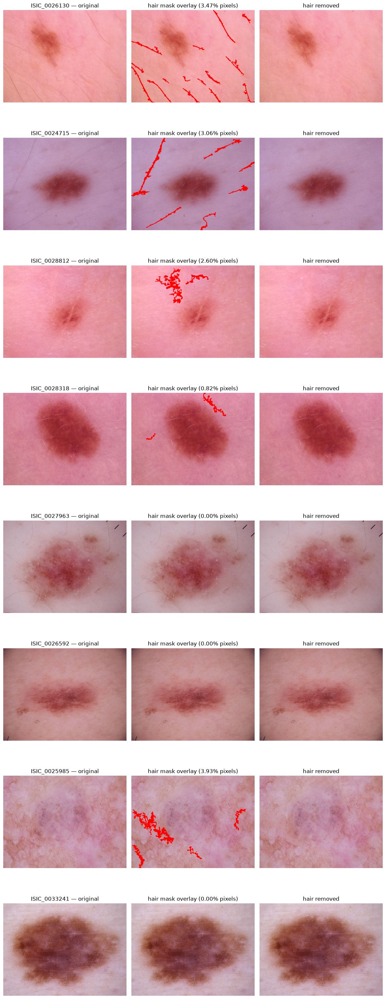


Check each row for:
  1. Red pixels tracing actual hair strands, at any angle (not just horizontal/vertical)
  2. NO red pixels inside the lesion boundary (pigment-network false-positive check)
  3. The 'hair removed' column looking visually clean where hair was detected


In [14]:
"""
05_08_validation_driver.txt
Hair removal — Validation Driver.

Runs the full chain (detect -> remove) on a small random sample and
displays a 3-column visual grid per image: original / hair mask overlaid
in red / hair-removed result.

The red-overlay view specifically matters here: it's what catches a
detector wrongly tracing pigment-network texture as hair, since that shows
up as red pixels appearing INSIDE the lesion boundary rather than only on
background skin. Check for that specifically before trusting the output.

This is a one-off diagnostic — the sample seed here is just for
reproducible sampling during this validation step, not the pipeline's
official random seed (that gets fixed later in Section 11).
"""

import random
import cv2
import matplotlib.pyplot as plt

VALIDATION_SAMPLE_SIZE = 8
VALIDATION_SEED = 42  # local to this validation step only


def find_image_path(image_id):
    for ext in (".jpg", ".jpeg", ".png"):
        candidate = IMAGES_DIR / f"{image_id}{ext}"
        if candidate.exists():
            return candidate
    raise FileNotFoundError(f"No image file found for {image_id}")


# --- Pick a random sample of image_ids ---
all_image_ids = [f.stem for f in IMAGES_DIR.iterdir() if f.suffix.lower() in (".jpg", ".jpeg", ".png")]
random.seed(VALIDATION_SEED)
sample_ids = random.sample(all_image_ids, VALIDATION_SAMPLE_SIZE)

print(f"Validating on {VALIDATION_SAMPLE_SIZE} images: {sample_ids}\n")

# --- Run the chain and collect results ---
results = []
for image_id in sample_ids:
    img_path = find_image_path(image_id)
    image_bgr = cv2.imread(str(img_path))
    lesion_mask = load_lesion_mask(image_id, target_shape=image_bgr.shape[:2])

    hair_mask = detect_hair_mask(image_bgr, lesion_mask)
    removed_bgr = remove_hair(image_bgr, hair_mask)
    save_hair_mask(hair_mask, image_id)

    hair_pct = (hair_mask == 255).sum() / hair_mask.size * 100

    overlay_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB).copy()
    overlay_rgb[hair_mask == 255] = [255, 0, 0]

    results.append({
        "image_id": image_id,
        "original_rgb": cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB),
        "overlay_rgb": overlay_rgb,
        "removed_rgb": cv2.cvtColor(removed_bgr, cv2.COLOR_BGR2RGB),
        "hair_pct": hair_pct,
    })

# --- Display grid ---
fig, axes = plt.subplots(len(results), 3, figsize=(12, 4 * len(results)))
for i, r in enumerate(results):
    axes[i, 0].imshow(r["original_rgb"])
    axes[i, 0].set_title(f"{r['image_id']} — original")
    axes[i, 1].imshow(r["overlay_rgb"])
    axes[i, 1].set_title(f"hair mask overlay ({r['hair_pct']:.2f}% pixels)")
    axes[i, 2].imshow(r["removed_rgb"])
    axes[i, 2].set_title("hair removed")
    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()

print("\nCheck each row for:")
print("  1. Red pixels tracing actual hair strands, at any angle (not just horizontal/vertical)")
print("  2. NO red pixels inside the lesion boundary (pigment-network false-positive check)")
print("  3. The 'hair removed' column looking visually clean where hair was detected")

In [15]:
"""
05_09_full_dataset_run.txt
Hair removal — Full Dataset Run (Section 5).

Runs detect_hair_mask() + a pixel-diff sanity check across all 10,015
HAM10000 images. Persists hair masks to disk (via save_hair_mask()) and
writes per-image stats (hair_pct, pixel_diff_mean) to CSV.

Does NOT save the 10,015 hair-removed images to disk — only masks + stats.
The actual hair-removed images are written once, later, in Section 12's
combined single-pass pipeline, per Phase-1_Updated.md's warning against
redundant lossy re-encoding of intermediate stages.

Requires 05_00 through 05_07 already defined (run those cells first).
"""

import cv2
import numpy as np
import pandas as pd
from tqdm import tqdm

metadata = pd.read_csv(
    BASE_DIR / "Resources" / "Dataset" / "HAM10000" / "HAM10000_metadata.tab", sep="\t"
)
dx_lookup = dict(zip(metadata["image_id"], metadata["dx"]))


def find_image_path(image_id):
    for ext in (".jpg", ".jpeg", ".png"):
        candidate = IMAGES_DIR / f"{image_id}{ext}"
        if candidate.exists():
            return candidate
    raise FileNotFoundError(f"No image file found for {image_id}")


all_image_ids = sorted(
    f.stem for f in IMAGES_DIR.iterdir() if f.suffix.lower() in (".jpg", ".jpeg", ".png")
)

print("=" * 60)
print("HAIR REMOVAL — FULL DATASET RUN — Phase 1 P2")
print("=" * 60)
print(f"Processing {len(all_image_ids)} images...\n")

dilate_kernel = cv2.getStructuringElement(
    cv2.MORPH_RECT, (DILATE_KERNEL_SIZE, DILATE_KERNEL_SIZE)
)

rows = []
for image_id in tqdm(all_image_ids, desc="Hair detection + removal"):
    img_path = find_image_path(image_id)
    image_bgr = cv2.imread(str(img_path))

    if image_bgr is None:
        rows.append({
            "image_id": image_id, "dx": dx_lookup.get(image_id),
            "hair_pct": np.nan, "pixel_diff_mean": np.nan,
        })
        continue

    lesion_mask = load_lesion_mask(image_id, target_shape=image_bgr.shape[:2])
    hair_mask = detect_hair_mask(image_bgr, lesion_mask)
    save_hair_mask(hair_mask, image_id)

    hair_pct = (hair_mask == 255).sum() / hair_mask.size * 100

    # Pixel-diff sanity check — confirms removal genuinely modifies pixels, not a no-op
    dilated_mask = cv2.dilate(hair_mask, dilate_kernel, iterations=DILATE_ITERATIONS)
    if (dilated_mask == 255).sum() > 0:
        removed_bgr = remove_hair(image_bgr, hair_mask)
        diff = cv2.absdiff(image_bgr, removed_bgr)
        pixel_diff_mean = float(diff[dilated_mask == 255].mean())
    else:
        pixel_diff_mean = 0.0  # nothing detected, nothing to remove

    rows.append({
        "image_id": image_id,
        "dx": dx_lookup.get(image_id),
        "hair_pct": hair_pct,
        "pixel_diff_mean": pixel_diff_mean,
    })

stats_df = pd.DataFrame(rows)
stats_path = ARTIFACTS_DIR / "hair_coverage_stats.csv"
stats_df.to_csv(stats_path, index=False)
print(f"\nPer-image stats written to: {stats_path}")

# --- Summary ---
print("\n--- Hair coverage summary ---")
print(f"Mean hair_pct:   {stats_df['hair_pct'].mean():.2f}%")
print(f"Median hair_pct: {stats_df['hair_pct'].median():.2f}%")
print(f"Max hair_pct:    {stats_df['hair_pct'].max():.2f}%")

zero_detect = stats_df[stats_df["hair_pct"] == 0.0]
zero_pct_overall = len(zero_detect) / len(stats_df) * 100
print(f"\nImages with 0% detection: {len(zero_detect)} ({zero_pct_overall:.1f}% of dataset)")

print("\n--- Zero-detection rate by class ---")
by_class = stats_df.groupby("dx")["hair_pct"].agg(
    total="count",
    zero_detect_count=lambda x: (x == 0.0).sum(),
).reset_index()
by_class["zero_detect_pct"] = (by_class["zero_detect_count"] / by_class["total"] * 100).round(2)
print(by_class.to_string(index=False))

print("\n--- Pixel-diff sanity check (images with detected hair only) ---")
detected = stats_df[stats_df["hair_pct"] > 0]
print(f"Mean pixel_diff_mean: {detected['pixel_diff_mean'].mean():.2f}")
print(f"Min pixel_diff_mean:  {detected['pixel_diff_mean'].min():.2f}")
print("(A near-zero value here on any image would indicate removal did nothing.)")

failed = stats_df["hair_pct"].isna().sum()
if failed:
    print(f"\nNOTE: {failed} image(s) failed to load — check separately.")

print("=" * 60)

HAIR REMOVAL — FULL DATASET RUN — Phase 1 P2
Processing 10015 images...



Hair detection + removal: 100%|██████████| 10015/10015 [02:41<00:00, 61.92it/s]



Per-image stats written to: T:\Thesis - Development\Resources\Artifacts\Phase 1 - P2\hair_coverage_stats.csv

--- Hair coverage summary ---
Mean hair_pct:   1.34%
Median hair_pct: 0.41%
Max hair_pct:    27.22%

Images with 0% detection: 2874 (28.7% of dataset)

--- Zero-detection rate by class ---
   dx  total  zero_detect_count  zero_detect_pct
akiec    327                 67            20.49
  bcc    514                104            20.23
  bkl   1099                340            30.94
   df    115                 22            19.13
  mel   1113                404            36.30
   nv   6705               1901            28.35
 vasc    142                 36            25.35

--- Pixel-diff sanity check (images with detected hair only) ---
Mean pixel_diff_mean: 13.52
Min pixel_diff_mean:  2.10
(A near-zero value here on any image would indicate removal did nothing.)


Zero Detection Sanity Check

ZERO-DETECTION SANITY CHECK — Phase 1 P2
Total zero-detection images: 2874 (28.7% of dataset)

--- Composition of the zero-detection group (share of the 2,874, by class) ---
   dx  count  pct_of_zero_detect_group
   nv   1901                     66.14
  mel    404                     14.06
  bkl    340                     11.83
  bcc    104                      3.62
akiec     67                      2.33
 vasc     36                      1.25
   df     22                      0.77

Displaying 14 sample images (2 per class)...


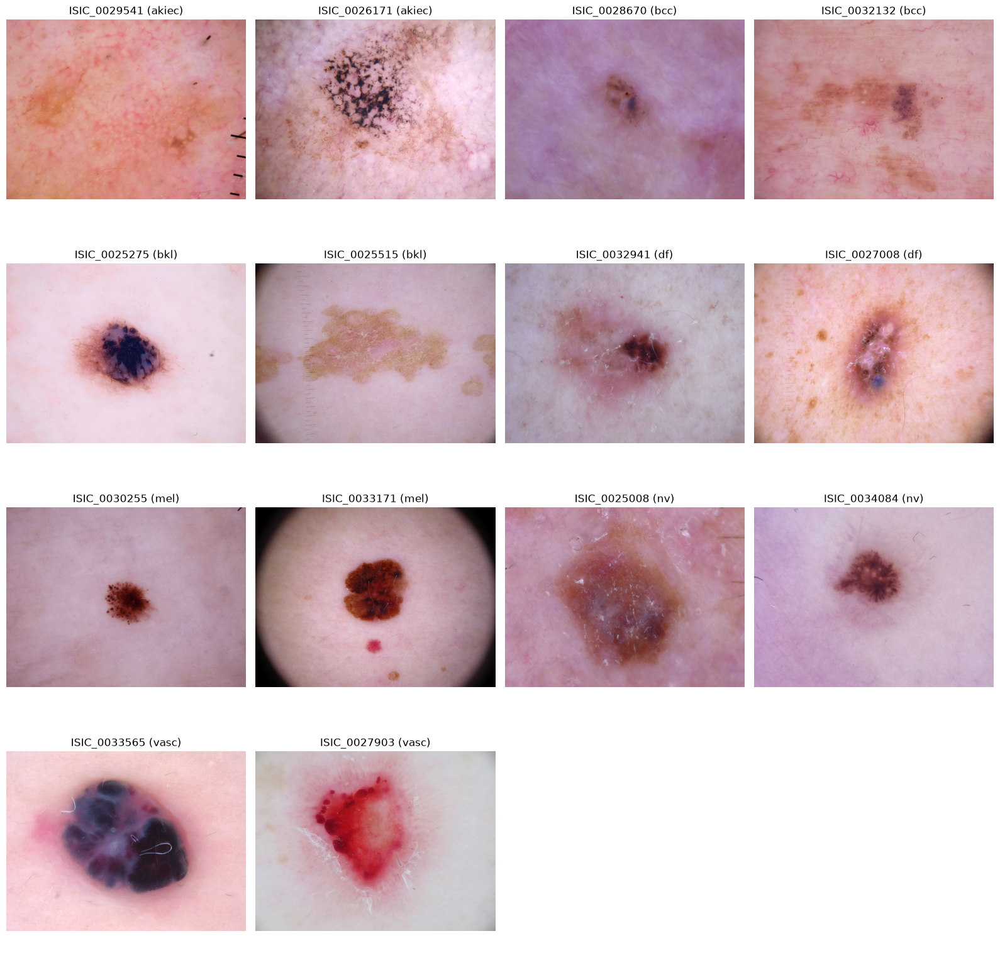


For each image, judge: genuinely hair-free, or visible hair the detector missed?


In [16]:
"""
05_10_zero_detection_sanity_check.txt
Hair removal — Zero-Detection Sanity Check (Section 5).

Filters the zero-detection group (hair_pct == 0.0) from the full-dataset
run and displays a stratified sample (2 per class) for visual inspection.

Purpose: distinguish "genuinely hair-free" from "detector missed dense
hair" — a distinction that can no longer be assumed after ISIC_0027963
proved a 0% reading doesn't guarantee hair-free.

This is a one-off diagnostic; the sample seed here is local to this check
only, not the pipeline's official random seed (Section 11).
"""

import random
import cv2
import pandas as pd
import matplotlib.pyplot as plt

SAMPLE_PER_CLASS = 2
SANITY_CHECK_SEED = 7  # local to this check only

stats_df = pd.read_csv(ARTIFACTS_DIR / "hair_coverage_stats.csv")
zero_detect_df = stats_df[stats_df["hair_pct"] == 0.0]

print("=" * 60)
print("ZERO-DETECTION SANITY CHECK — Phase 1 P2")
print("=" * 60)
print(f"Total zero-detection images: {len(zero_detect_df)} "
      f"({len(zero_detect_df) / len(stats_df) * 100:.1f}% of dataset)\n")

print("--- Composition of the zero-detection group (share of the 2,874, by class) ---")
composition = zero_detect_df["dx"].value_counts().reset_index()
composition.columns = ["dx", "count"]
composition["pct_of_zero_detect_group"] = (composition["count"] / len(zero_detect_df) * 100).round(2)
print(composition.to_string(index=False))

# --- Stratified sample: SAMPLE_PER_CLASS per class ---
random.seed(SANITY_CHECK_SEED)
sample_rows = []
for dx_class in sorted(zero_detect_df["dx"].unique()):
    class_ids = zero_detect_df.loc[zero_detect_df["dx"] == dx_class, "image_id"].tolist()
    n = min(SAMPLE_PER_CLASS, len(class_ids))
    sample_ids = random.sample(class_ids, n)
    for image_id in sample_ids:
        sample_rows.append({"image_id": image_id, "dx": dx_class})

print(f"\nDisplaying {len(sample_rows)} sample images ({SAMPLE_PER_CLASS} per class)...")


def find_image_path(image_id):
    for ext in (".jpg", ".jpeg", ".png"):
        candidate = IMAGES_DIR / f"{image_id}{ext}"
        if candidate.exists():
            return candidate
    raise FileNotFoundError(f"No image file found for {image_id}")


n_cols = 4
n_rows = -(-len(sample_rows) // n_cols)  # ceil division
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 4 * n_rows))
axes = axes.flatten()

for i, row in enumerate(sample_rows):
    img_path = find_image_path(row["image_id"])
    img_bgr = cv2.imread(str(img_path))
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    axes[i].imshow(img_rgb)
    axes[i].set_title(f"{row['image_id']} ({row['dx']})")
    axes[i].axis("off")

for j in range(len(sample_rows), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

print("\nFor each image, judge: genuinely hair-free, or visible hair the detector missed?")

##### Contrast Enhancement (CLAHE)

In [9]:
"""
06_00_clahe_config.txt
CLAHE — configuration (Phase 1, P2, Section 6).
"""

CLIP_LIMIT = 1.5          # LOCKED — chosen via empirical comparison across candidate
                           # values (1.0/1.5/2.0/3.0) on an 8-image sample: best balance
                           # between meaningful contrast gain on flat/dull lesions and
                           # visible noise-amplification on the same images (see
                           # 06_04_clip_limit_comparison.txt for the full comparison)
TILE_GRID_SIZE = (8, 8)

print("CLAHE config loaded.")
print(f"  clip_limit: {CLIP_LIMIT}")
print(f"  tile_grid_size: {TILE_GRID_SIZE}")

CLAHE config loaded.
  clip_limit: 1.5
  tile_grid_size: (8, 8)


In [10]:
"""
06_01_apply_clahe.txt
CLAHE — Application function.

Applies CLAHE to the L (lightness) channel only, in LAB color space.
Never applied per-RGB-channel — that would shift hue, and lesion colour
is diagnostically meaningful (and relevant to the demographic
disaggregation contribution this thesis is built around).
"""

import cv2


def apply_clahe(image_bgr, clip_limit=CLIP_LIMIT, tile_grid_size=TILE_GRID_SIZE):
    """
    image_bgr: original color image (BGR)
    Returns: contrast-enhanced image (BGR), same shape as input
    """
    lab = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2LAB)
    l_channel, a_channel, b_channel = cv2.split(lab)

    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_grid_size)
    l_channel_enhanced = clahe.apply(l_channel)

    lab_enhanced = cv2.merge([l_channel_enhanced, a_channel, b_channel])
    return cv2.cvtColor(lab_enhanced, cv2.COLOR_LAB2BGR)

Validating on 8 images: ['ISIC_0030924', 'ISIC_0030544', 'ISIC_0027584', 'ISIC_0034127', 'ISIC_0027235', 'ISIC_0028078', 'ISIC_0028376', 'ISIC_0026489']



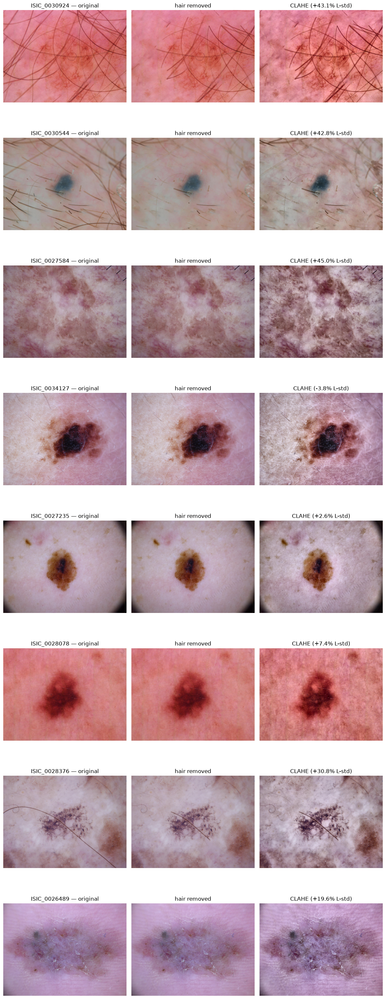


Check each row for visible graininess/blotchiness, especially on the highest-gain images.
This is the expected noise-amplification tradeoff, not a bug.


In [25]:
"""
06_02_validation_driver.txt
CLAHE — Validation Driver.

Chains hair removal (using already-persisted masks from Section 5) into
CLAHE on a small random sample, and displays original / hair-removed /
CLAHE-enhanced side by side. Reports per-image contrast gain (% change in
L-channel standard deviation) so the known noise-amplification tradeoff on
high-gain images can be checked visually before the full-dataset run.

Requires 06_00-06_01 and Section 5's 05_00-05_07 already defined.

This is a one-off diagnostic; the sample seed here is local to this
validation step only, not the pipeline's official random seed (Section 11).
"""

import random
import cv2
import numpy as np
import matplotlib.pyplot as plt

VALIDATION_SAMPLE_SIZE = 8
CLAHE_VALIDATION_SEED = 99  # local to this validation step only


def find_image_path(image_id):
    for ext in (".jpg", ".jpeg", ".png"):
        candidate = IMAGES_DIR / f"{image_id}{ext}"
        if candidate.exists():
            return candidate
    raise FileNotFoundError(f"No image file found for {image_id}")


def load_hair_mask(image_id):
    mask_path = HAIR_MASKS_DIR / f"{image_id}_hairmask.png"
    if not mask_path.exists():
        raise FileNotFoundError(f"No persisted hair mask found for {image_id} at {mask_path}")
    mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
    if mask is None:
        raise ValueError(f"Hair mask failed to load: {mask_path}")
    return mask


def l_channel_std(image_bgr):
    lab = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2LAB)
    return float(np.std(lab[:, :, 0]))


all_image_ids = [f.stem for f in IMAGES_DIR.iterdir() if f.suffix.lower() in (".jpg", ".jpeg", ".png")]
random.seed(CLAHE_VALIDATION_SEED)
sample_ids = random.sample(all_image_ids, VALIDATION_SAMPLE_SIZE)

print(f"Validating on {VALIDATION_SAMPLE_SIZE} images: {sample_ids}\n")

results = []
for image_id in sample_ids:
    img_path = find_image_path(image_id)
    image_bgr = cv2.imread(str(img_path))
    hair_mask = load_hair_mask(image_id)

    hair_removed_bgr = remove_hair(image_bgr, hair_mask)
    clahe_bgr = apply_clahe(hair_removed_bgr)

    std_before = l_channel_std(hair_removed_bgr)
    std_after = l_channel_std(clahe_bgr)
    contrast_gain_pct = (std_after - std_before) / std_before * 100 if std_before > 0 else float("nan")

    results.append({
        "image_id": image_id,
        "original_rgb": cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB),
        "hair_removed_rgb": cv2.cvtColor(hair_removed_bgr, cv2.COLOR_BGR2RGB),
        "clahe_rgb": cv2.cvtColor(clahe_bgr, cv2.COLOR_BGR2RGB),
        "contrast_gain_pct": contrast_gain_pct,
    })

fig, axes = plt.subplots(len(results), 3, figsize=(12, 4 * len(results)))
for i, r in enumerate(results):
    axes[i, 0].imshow(r["original_rgb"])
    axes[i, 0].set_title(f"{r['image_id']} — original")
    axes[i, 1].imshow(r["hair_removed_rgb"])
    axes[i, 1].set_title("hair removed")
    axes[i, 2].imshow(r["clahe_rgb"])
    axes[i, 2].set_title(f"CLAHE ({r['contrast_gain_pct']:+.1f}% L-std)")
    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()

print("\nCheck each row for visible graininess/blotchiness, especially on the highest-gain images.")
print("This is the expected noise-amplification tradeoff, not a bug.")

In [26]:
"""
06_03_full_dataset_run.txt
CLAHE — Full Dataset Run (Section 6).

Computes contrast gain (% change in L-channel std dev) across all 10,015
images, chaining hair removal (via already-persisted Section 5 masks) into
CLAHE. Writes results to CSV.

RESUMABLE: checks the output CSV for image_ids already completed and skips
them; each row is written and flushed to disk immediately after that image
finishes, so an interruption only loses the one image in progress, not
anything already done. Safe to stop and re-run this exact script as many
times as needed.

Does NOT save the 10,015 CLAHE-enhanced images to disk — stats only. The
actual enhanced images are written once, in Section 12's combined pipeline.

Requires 06_00-06_01 and Section 5's 05_00-05_07 already defined.
"""

import csv
import cv2
import numpy as np
import pandas as pd
from tqdm import tqdm

METADATA_PATH = BASE_DIR / "Resources" / "Dataset" / "HAM10000" / "HAM10000_metadata.tab"
OUTPUT_PATH = ARTIFACTS_DIR / "clahe_contrast_gain.csv"
FIELDNAMES = ["image_id", "dx", "l_std_before", "l_std_after", "contrast_gain_pct"]

metadata = pd.read_csv(METADATA_PATH, sep="\t")
dx_lookup = dict(zip(metadata["image_id"], metadata["dx"]))


def find_image_path(image_id):
    for ext in (".jpg", ".jpeg", ".png"):
        candidate = IMAGES_DIR / f"{image_id}{ext}"
        if candidate.exists():
            return candidate
    raise FileNotFoundError(f"No image file found for {image_id}")


def load_hair_mask(image_id):
    mask_path = HAIR_MASKS_DIR / f"{image_id}_hairmask.png"
    mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
    if mask is None:
        raise ValueError(f"Hair mask failed to load: {mask_path}")
    return mask


def l_channel_std(image_bgr):
    lab = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2LAB)
    return float(np.std(lab[:, :, 0]))


# --- Resume logic: figure out what's already done ---
if OUTPUT_PATH.exists():
    done_df = pd.read_csv(OUTPUT_PATH)
    completed_ids = set(done_df["image_id"])
    print(f"Resuming — {len(completed_ids)} image(s) already completed, will be skipped.")
else:
    completed_ids = set()
    with open(OUTPUT_PATH, "w", newline="") as f:
        csv.DictWriter(f, fieldnames=FIELDNAMES).writeheader()
    print("Starting fresh run.")

all_image_ids = sorted(
    f.stem for f in IMAGES_DIR.iterdir() if f.suffix.lower() in (".jpg", ".jpeg", ".png")
)
remaining_ids = [i for i in all_image_ids if i not in completed_ids]

print("=" * 60)
print("CLAHE — FULL DATASET RUN — Phase 1 P2")
print("=" * 60)
print(f"Total images: {len(all_image_ids)} | Already done: {len(completed_ids)} | Remaining: {len(remaining_ids)}\n")

with open(OUTPUT_PATH, "a", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=FIELDNAMES)

    for image_id in tqdm(remaining_ids, desc="CLAHE contrast gain"):
        img_path = find_image_path(image_id)
        image_bgr = cv2.imread(str(img_path))

        if image_bgr is None:
            writer.writerow({
                "image_id": image_id, "dx": dx_lookup.get(image_id),
                "l_std_before": np.nan, "l_std_after": np.nan, "contrast_gain_pct": np.nan,
            })
            f.flush()
            continue

        hair_mask = load_hair_mask(image_id)
        hair_removed_bgr = remove_hair(image_bgr, hair_mask)
        clahe_bgr = apply_clahe(hair_removed_bgr)

        std_before = l_channel_std(hair_removed_bgr)
        std_after = l_channel_std(clahe_bgr)
        contrast_gain_pct = (std_after - std_before) / std_before * 100 if std_before > 0 else np.nan

        writer.writerow({
            "image_id": image_id,
            "dx": dx_lookup.get(image_id),
            "l_std_before": round(std_before, 2),
            "l_std_after": round(std_after, 2),
            "contrast_gain_pct": round(contrast_gain_pct, 2) if not np.isnan(contrast_gain_pct) else np.nan,
        })
        f.flush()

print(f"\nAll results written to: {OUTPUT_PATH}")

# --- Summary ---
final_df = pd.read_csv(OUTPUT_PATH)
print("\n--- Contrast gain summary ---")
print(f"Mean gain:   {final_df['contrast_gain_pct'].mean():.2f}%")
print(f"Median gain: {final_df['contrast_gain_pct'].median():.2f}%")
print(f"Min gain:    {final_df['contrast_gain_pct'].min():.2f}%")
print(f"Max gain:    {final_df['contrast_gain_pct'].max():.2f}%")

high_gain_threshold = 40.0
high_gain_count = (final_df["contrast_gain_pct"] >= high_gain_threshold).sum()
print(f"\nImages with gain >= {high_gain_threshold}%: {high_gain_count} "
      f"({high_gain_count / len(final_df) * 100:.2f}% of dataset)")
print("(High-gain images are where the noise-amplification tradeoff is most visible —")
print(" worth a quick visual spot-check of a few before locking clip_limit as final.)")

print("=" * 60)

Starting fresh run.
CLAHE — FULL DATASET RUN — Phase 1 P2
Total images: 10015 | Already done: 0 | Remaining: 10015



CLAHE contrast gain: 100%|██████████| 10015/10015 [02:27<00:00, 67.97it/s]


All results written to: T:\Thesis - Development\Resources\Artifacts\Phase 1 - P2\clahe_contrast_gain.csv

--- Contrast gain summary ---
Mean gain:   18.61%
Median gain: 15.97%
Min gain:    -11.39%
Max gain:    89.72%

Images with gain >= 40.0%: 993 (9.92% of dataset)
(High-gain images are where the noise-amplification tradeoff is most visible —
 worth a quick visual spot-check of a few before locking clip_limit as final.)


Comparing clip_limit values [1.0, 1.5, 2.0, 3.0] on 8 images: ['ISIC_0030924', 'ISIC_0030544', 'ISIC_0027584', 'ISIC_0034127', 'ISIC_0027235', 'ISIC_0028078', 'ISIC_0028376', 'ISIC_0026489']



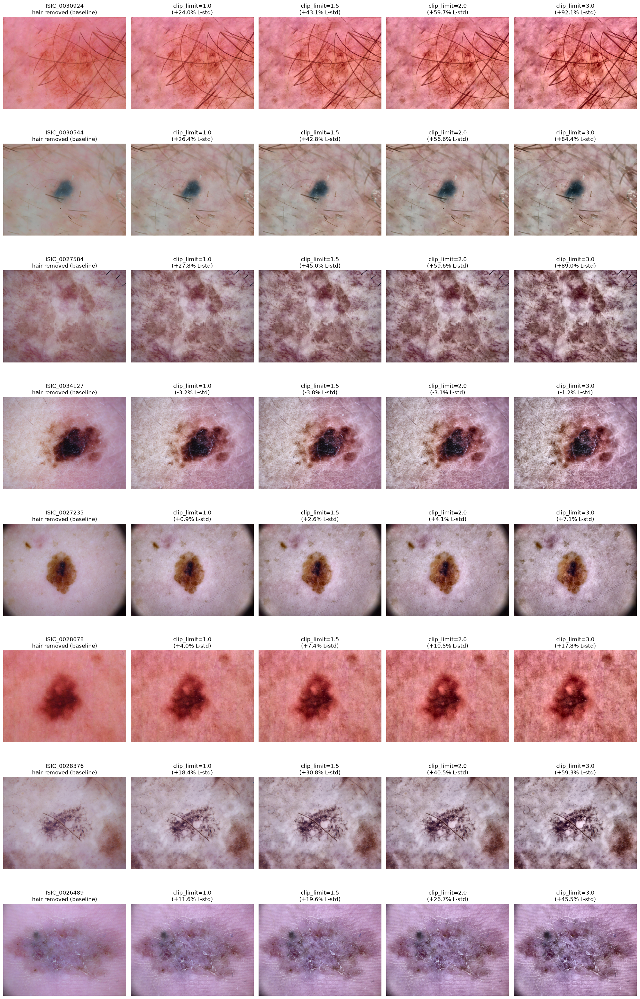


--- Contrast gain per clip_limit, across the 8-image sample ---
             mean    std   min    max
clip_limit                           
1.0         13.74  12.17 -3.20  27.83
1.5         23.43  19.74 -3.81  45.01
2.0         31.83  25.93 -3.08  59.75
3.0         49.27  37.94 -1.18  92.14

Compare visually:
  - Does the gentlest value (1.0) still meaningfully help dull lesions?
  - Does the strongest value (3.0) make graininess noticeably worse than 2.0,
    specifically on the flattest/lowest-contrast images in the sample?


In [27]:
"""
06_04_clip_limit_comparison.txt
CLAHE — Clip Limit Comparison (Section 6).

Tests multiple candidate clip_limit values on the SAME 8 validation images
used in 06_02 (same seed), to compare enhancement strength against
noise-amplification side-by-side before locking a final value.

Displays a grid: each row is one image, columns are hair-removed baseline
-> CLAHE at each candidate clip_limit, labeled with contrast gain %.
Also prints a summary table of contrast gain per candidate across the
sample.

This is a one-off comparison script, not meant to be reused after a final
clip_limit is chosen.

Requires Section 5's 05_00-05_07 and 06_00-06_01 already defined.
"""

import random
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

VALIDATION_SAMPLE_SIZE = 8
CLAHE_VALIDATION_SEED = 99  # same seed as 06_02, for a fair side-by-side comparison
CANDIDATE_CLIP_LIMITS = [1.0, 1.5, 2.0, 3.0]


def find_image_path(image_id):
    for ext in (".jpg", ".jpeg", ".png"):
        candidate = IMAGES_DIR / f"{image_id}{ext}"
        if candidate.exists():
            return candidate
    raise FileNotFoundError(f"No image file found for {image_id}")


def load_hair_mask(image_id):
    mask_path = HAIR_MASKS_DIR / f"{image_id}_hairmask.png"
    mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
    if mask is None:
        raise ValueError(f"Hair mask failed to load: {mask_path}")
    return mask


def l_channel_std(image_bgr):
    lab = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2LAB)
    return float(np.std(lab[:, :, 0]))


all_image_ids = [f.stem for f in IMAGES_DIR.iterdir() if f.suffix.lower() in (".jpg", ".jpeg", ".png")]
random.seed(CLAHE_VALIDATION_SEED)
sample_ids = random.sample(all_image_ids, VALIDATION_SAMPLE_SIZE)

print(f"Comparing clip_limit values {CANDIDATE_CLIP_LIMITS} on {VALIDATION_SAMPLE_SIZE} images: {sample_ids}\n")

# --- Run every candidate on every sample image ---
records = []        # for the summary table
image_results = {}  # for the grid display

for image_id in sample_ids:
    img_path = find_image_path(image_id)
    image_bgr = cv2.imread(str(img_path))
    hair_mask = load_hair_mask(image_id)
    hair_removed_bgr = remove_hair(image_bgr, hair_mask)
    std_before = l_channel_std(hair_removed_bgr)

    row_images = {"baseline": cv2.cvtColor(hair_removed_bgr, cv2.COLOR_BGR2RGB)}
    row_gains = {}

    for clip in CANDIDATE_CLIP_LIMITS:
        clahe_bgr = apply_clahe(hair_removed_bgr, clip_limit=clip, tile_grid_size=TILE_GRID_SIZE)
        std_after = l_channel_std(clahe_bgr)
        gain_pct = (std_after - std_before) / std_before * 100 if std_before > 0 else float("nan")

        row_images[clip] = cv2.cvtColor(clahe_bgr, cv2.COLOR_BGR2RGB)
        row_gains[clip] = gain_pct

        records.append({"image_id": image_id, "clip_limit": clip, "contrast_gain_pct": gain_pct})

    image_results[image_id] = {"images": row_images, "gains": row_gains}

# --- Display grid: baseline + one column per candidate ---
n_cols = 1 + len(CANDIDATE_CLIP_LIMITS)
n_rows = len(sample_ids)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 4 * n_rows))

for i, image_id in enumerate(sample_ids):
    r = image_results[image_id]
    axes[i, 0].imshow(r["images"]["baseline"])
    axes[i, 0].set_title(f"{image_id}\nhair removed (baseline)")
    axes[i, 0].axis("off")

    for j, clip in enumerate(CANDIDATE_CLIP_LIMITS, start=1):
        axes[i, j].imshow(r["images"][clip])
        axes[i, j].set_title(f"clip_limit={clip}\n({r['gains'][clip]:+.1f}% L-std)")
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()

# --- Summary comparison table ---
records_df = pd.DataFrame(records)
summary = records_df.groupby("clip_limit")["contrast_gain_pct"].agg(["mean", "std", "min", "max"]).round(2)
print("\n--- Contrast gain per clip_limit, across the 8-image sample ---")
print(summary.to_string())

print("\nCompare visually:")
print("  - Does the gentlest value (1.0) still meaningfully help dull lesions?")
print("  - Does the strongest value (3.0) make graininess noticeably worse than 2.0,")
print("    specifically on the flattest/lowest-contrast images in the sample?")

##### Colour Normalisation — Not Implemented

##### Resize

In [28]:
"""
08_00_lesion_clip_check.txt
Resize/Crop — Empirical Lesion-Clipping Check (Section 8).

Before deciding whether to centre-crop or pad HAM10000 images to square,
this checks — using the actual lesion masks, across the full dataset —
how much lesion area a naive, image-centred square crop would cut off.

For each image: determine the centred square crop region based on its
ACTUAL dimensions (not an assumed 600x450), then compute what percentage
of lesion pixels (from the mask) would fall OUTSIDE that crop region.
More informative than a simple "touches the edge or not" flag, since it
distinguishes a lesion barely grazing the boundary from one substantially
cut off.

Requires 05_00 (for MASKS_DIR) and 05_04 (for load_lesion_mask) already
defined.
"""

import numpy as np
import pandas as pd
from tqdm import tqdm

METADATA_PATH = BASE_DIR / "Resources" / "Dataset" / "HAM10000" / "HAM10000_metadata.tab"
metadata = pd.read_csv(METADATA_PATH, sep="\t")
dx_lookup = dict(zip(metadata["image_id"], metadata["dx"]))

all_image_ids = sorted(
    f.stem.replace("_segmentation", "") for f in MASKS_DIR.iterdir()
    if f.suffix.lower() == ".png" and "__MACOSX" not in f.parts and not f.name.startswith("._")
)

print("=" * 60)
print("LESION-CLIPPING CHECK — Centred Square Crop — Phase 1 P2")
print("=" * 60)
print(f"Checking {len(all_image_ids)} images...\n")

rows = []
for image_id in tqdm(all_image_ids, desc="Checking lesion clipping"):
    mask = load_lesion_mask(image_id)
    h, w = mask.shape
    crop_size = min(h, w)

    if w > h:
        row_start, row_end = 0, h
        col_start = (w - crop_size) // 2
        col_end = col_start + crop_size
    elif h > w:
        col_start, col_end = 0, w
        row_start = (h - crop_size) // 2
        row_end = row_start + crop_size
    else:
        row_start, row_end, col_start, col_end = 0, h, 0, w

    total_lesion_px = int((mask == 255).sum())
    cropped_region = mask[row_start:row_end, col_start:col_end]
    inside_lesion_px = int((cropped_region == 255).sum())

    pct_lost = (
        (total_lesion_px - inside_lesion_px) / total_lesion_px * 100
        if total_lesion_px > 0 else np.nan
    )

    rows.append({
        "image_id": image_id,
        "dx": dx_lookup.get(image_id),
        "height": h,
        "width": w,
        "total_lesion_px": total_lesion_px,
        "pct_lesion_lost": pct_lost,
    })

results_df = pd.DataFrame(rows)
output_path = ARTIFACTS_DIR / "lesion_clip_check.csv"
results_df.to_csv(output_path, index=False)
print(f"\nResults written to: {output_path}")

# --- Dimension summary ---
print("\n--- Image dimensions found ---")
dim_counts = results_df.groupby(["height", "width"]).size().reset_index(name="count")
print(dim_counts.to_string(index=False))

# --- Clipping severity summary ---
print("\n--- Lesion-clipping severity (centred square crop) ---")
n = len(results_df)
zero_loss = (results_df["pct_lesion_lost"] == 0).sum()
any_loss = (results_df["pct_lesion_lost"] > 0).sum()
over_1pct = (results_df["pct_lesion_lost"] > 1).sum()
over_5pct = (results_df["pct_lesion_lost"] > 5).sum()
over_10pct = (results_df["pct_lesion_lost"] > 10).sum()

print(f"0% lesion lost (fully contained):  {zero_loss} ({zero_loss / n * 100:.2f}%)")
print(f"Any loss (>0%):                     {any_loss} ({any_loss / n * 100:.2f}%)")
print(f"Loss >1%:                           {over_1pct} ({over_1pct / n * 100:.2f}%)")
print(f"Loss >5%:                           {over_5pct} ({over_5pct / n * 100:.2f}%)")
print(f"Loss >10%:                          {over_10pct} ({over_10pct / n * 100:.2f}%)")
print(f"\nMax loss observed: {results_df['pct_lesion_lost'].max():.2f}%")

print("\n--- Loss >5% breakdown by class ---")
severe = results_df[results_df["pct_lesion_lost"] > 5]
if len(severe) > 0:
    by_class = severe.groupby("dx").size().reset_index(name="count")
    print(by_class.to_string(index=False))
else:
    print("None.")

print("=" * 60)

LESION-CLIPPING CHECK — Centred Square Crop — Phase 1 P2
Checking 10015 images...



Checking lesion clipping: 100%|██████████| 10015/10015 [00:09<00:00, 1038.46it/s]



Results written to: T:\Thesis - Development\Resources\Artifacts\Phase 1 - P2\lesion_clip_check.csv

--- Image dimensions found ---
 height  width  count
    450    600  10015

--- Lesion-clipping severity (centred square crop) ---
0% lesion lost (fully contained):  7308 (72.97%)
Any loss (>0%):                     2707 (27.03%)
Loss >1%:                           2113 (21.10%)
Loss >5%:                           1285 (12.83%)
Loss >10%:                          711 (7.10%)

Max loss observed: 29.46%

--- Loss >5% breakdown by class ---
   dx  count
akiec    100
  bcc     61
  bkl    192
   df     17
  mel    205
   nv    704
 vasc      6


In [29]:
"""
08_01_lesion_centered_crop_check.txt
Resize/Crop — Lesion-Centred Crop Check (Section 8).

Tests an alternative to naive image-centred cropping: since every HAM10000
image is uniformly 600x450 (confirmed in 08_00), a centred square crop
always keeps the full height and only ever trims width — meaning every
instance of lesion clipping found in 08_00 was purely horizontal.

This script instead centres the 450-wide crop window on each lesion's OWN
horizontal centroid (from its mask), sliding left/right as needed, clamped
so the window never goes outside the image (0 to 150px of available
horizontal slack). Compares directly against 08_00's image-centred results.

Requires 05_00 (for MASKS_DIR) and 05_04 (for load_lesion_mask) already
defined.
"""

import numpy as np
import pandas as pd
from tqdm import tqdm

METADATA_PATH = BASE_DIR / "Resources" / "Dataset" / "HAM10000" / "HAM10000_metadata.tab"
metadata = pd.read_csv(METADATA_PATH, sep="\t")
dx_lookup = dict(zip(metadata["image_id"], metadata["dx"]))

CROP_SIZE = 450  # matches the shorter dimension (height), confirmed uniform in 08_00

all_image_ids = sorted(
    f.stem.replace("_segmentation", "") for f in MASKS_DIR.iterdir()
    if f.suffix.lower() == ".png" and "__MACOSX" not in f.parts and not f.name.startswith("._")
)

print("=" * 60)
print("LESION-CENTRED CROP CHECK — Phase 1 P2")
print("=" * 60)
print(f"Checking {len(all_image_ids)} images...\n")

rows = []
for image_id in tqdm(all_image_ids, desc="Checking lesion-centred crop"):
    mask = load_lesion_mask(image_id)
    h, w = mask.shape  # expected (450, 600)

    lesion_cols = np.where(mask == 255)[1]
    if len(lesion_cols) == 0:
        rows.append({
            "image_id": image_id, "dx": dx_lookup.get(image_id),
            "total_lesion_px": 0, "pct_lesion_lost": np.nan, "was_clamped": False,
        })
        continue

    centroid_col = lesion_cols.mean()
    ideal_col_start = int(round(centroid_col - CROP_SIZE / 2))
    max_col_start = w - CROP_SIZE  # 150, given w=600
    col_start = max(0, min(ideal_col_start, max_col_start))
    was_clamped = col_start != ideal_col_start
    col_end = col_start + CROP_SIZE

    total_lesion_px = int((mask == 255).sum())
    cropped_region = mask[:, col_start:col_end]  # full height, since height already == CROP_SIZE
    inside_lesion_px = int((cropped_region == 255).sum())
    pct_lost = (total_lesion_px - inside_lesion_px) / total_lesion_px * 100

    rows.append({
        "image_id": image_id,
        "dx": dx_lookup.get(image_id),
        "total_lesion_px": total_lesion_px,
        "pct_lesion_lost": pct_lost,
        "was_clamped": was_clamped,
    })

results_df = pd.DataFrame(rows)
output_path = ARTIFACTS_DIR / "lesion_centered_crop_check.csv"
results_df.to_csv(output_path, index=False)
print(f"\nResults written to: {output_path}")

# --- Clipping severity summary ---
n = len(results_df)
print("\n--- Lesion-clipping severity (lesion-centred crop) ---")
zero_loss = (results_df["pct_lesion_lost"] == 0).sum()
any_loss = (results_df["pct_lesion_lost"] > 0).sum()
over_1pct = (results_df["pct_lesion_lost"] > 1).sum()
over_5pct = (results_df["pct_lesion_lost"] > 5).sum()
over_10pct = (results_df["pct_lesion_lost"] > 10).sum()

print(f"0% lesion lost (fully contained):  {zero_loss} ({zero_loss / n * 100:.2f}%)")
print(f"Any loss (>0%):                     {any_loss} ({any_loss / n * 100:.2f}%)")
print(f"Loss >1%:                           {over_1pct} ({over_1pct / n * 100:.2f}%)")
print(f"Loss >5%:                           {over_5pct} ({over_5pct / n * 100:.2f}%)")
print(f"Loss >10%:                          {over_10pct} ({over_10pct / n * 100:.2f}%)")
print(f"\nMax loss observed: {results_df['pct_lesion_lost'].max():.2f}%")

clamped_count = results_df["was_clamped"].sum()
print(f"\nImages where the ideal centred window had to be clamped to stay in-bounds: "
      f"{clamped_count} ({clamped_count / n * 100:.2f}%)")

print("\n--- Loss >5% breakdown by class (lesion-centred) ---")
severe = results_df[results_df["pct_lesion_lost"] > 5]
if len(severe) > 0:
    by_class = severe.groupby("dx").size().reset_index(name="count")
    print(by_class.to_string(index=False))
else:
    print("None.")

# --- Direct comparison against image-centred results (08_00) ---
image_centred_path = ARTIFACTS_DIR / "lesion_clip_check.csv"
if image_centred_path.exists():
    image_centred_df = pd.read_csv(image_centred_path)
    print("\n" + "=" * 60)
    print("DIRECT COMPARISON: image-centred (08_00) vs lesion-centred (this script)")
    print("=" * 60)
    comparison = pd.DataFrame({
        "metric": ["0% loss", "any loss (>0%)", "loss >1%", "loss >5%", "loss >10%", "max loss %"],
        "image_centred": [
            (image_centred_df["pct_lesion_lost"] == 0).sum(),
            (image_centred_df["pct_lesion_lost"] > 0).sum(),
            (image_centred_df["pct_lesion_lost"] > 1).sum(),
            (image_centred_df["pct_lesion_lost"] > 5).sum(),
            (image_centred_df["pct_lesion_lost"] > 10).sum(),
            round(image_centred_df["pct_lesion_lost"].max(), 2),
        ],
        "lesion_centred": [
            zero_loss, any_loss, over_1pct, over_5pct, over_10pct,
            round(results_df["pct_lesion_lost"].max(), 2),
        ],
    })
    print(comparison.to_string(index=False))
else:
    print("\n(08_00's lesion_clip_check.csv not found — skipping direct comparison table.)")

print("=" * 60)

LESION-CENTRED CROP CHECK — Phase 1 P2
Checking 10015 images...



Checking lesion-centred crop: 100%|██████████| 10015/10015 [00:18<00:00, 544.70it/s]


Results written to: T:\Thesis - Development\Resources\Artifacts\Phase 1 - P2\lesion_centered_crop_check.csv

--- Lesion-clipping severity (lesion-centred crop) ---
0% lesion lost (fully contained):  7930 (79.18%)
Any loss (>0%):                     2085 (20.82%)
Loss >1%:                           1606 (16.04%)
Loss >5%:                           974 (9.73%)
Loss >10%:                          520 (5.19%)

Max loss observed: 25.00%

Images where the ideal centred window had to be clamped to stay in-bounds: 345 (3.44%)

--- Loss >5% breakdown by class (lesion-centred) ---
   dx  count
akiec     79
  bcc     48
  bkl    156
   df      8
  mel    174
   nv    505
 vasc      4

DIRECT COMPARISON: image-centred (08_00) vs lesion-centred (this script)
        metric  image_centred  lesion_centred
       0% loss        7308.00          7930.0
any loss (>0%)        2707.00          2085.0
      loss >1%        2113.00          1606.0
      loss >5%        1285.00           974.0
     loss >10

In [11]:
"""
08_02_adaptive_crop_config.txt
Resize/Crop — Adaptive Crop/Pad configuration (Phase 1, P2, Section 8).
"""

import cv2

IMAGE_HEIGHT = 450    # confirmed uniform across all 10,015 HAM10000 images (08_00)
IMAGE_WIDTH = 600     # confirmed uniform across all 10,015 HAM10000 images (08_00)
BASE_CROP_SIZE = 450  # default square crop when the lesion fits within it

LESION_MARGIN_PX = 10  # small buffer added on each side of the lesion's bounding
                        # box when it doesn't fit BASE_CROP_SIZE, so the lesion
                        # isn't touching the crop edge exactly

# Fill mode for IMAGE padding only. Masks are ALWAYS padded with constant 0
# (background) regardless of this setting — padding is by definition not
# lesion, no exception.
IMAGE_PAD_BORDER_TYPE = cv2.BORDER_REFLECT_101  # mirrors real skin texture across
                                                  # the boundary rather than a hard
                                                  # black edge or a smeared replication,
                                                  # to minimise how visually distinctive
                                                  # padded images look (shortcut-learning
                                                  # risk, since padding rate correlates
                                                  # with lesion width, which correlates
                                                  # with class)

RESIZE_TARGET = 300  # EfficientNet-B3's required input size

print("Adaptive crop/pad config loaded.")
print(f"  Base crop size: {BASE_CROP_SIZE}x{BASE_CROP_SIZE}")
print(f"  Lesion margin: {LESION_MARGIN_PX}px per side")
print("  Image pad border type: BORDER_REFLECT_101 (masks always use constant 0)")
print(f"  Resize target: {RESIZE_TARGET}x{RESIZE_TARGET}")

Adaptive crop/pad config loaded.
  Base crop size: 450x450
  Lesion margin: 10px per side
  Image pad border type: BORDER_REFLECT_101 (masks always use constant 0)
  Resize target: 300x300


In [12]:
"""
08_03_adaptive_crop_functions.txt
Resize/Crop — Adaptive Crop/Pad Functions (Section 8).

Computes, per image, the SQUARE crop/pad region guaranteed to contain the
entire lesion (plus a small margin), using the actual lesion mask. Most
images resolve to a standard 450x450 crop with zero padding; a minority
(where the lesion's own width exceeds 450px) get a wider crop, padded
vertically just enough to stay square — so padding is only ever applied
where structurally necessary, not as a blanket transform.

The SAME plan is applied to both the image and its mask, guaranteeing
identical geometric transforms (required for Phase 4's Dice/IoU to be
valid). Masks are ALWAYS padded with constant 0 (background) regardless
of the image's fill mode — padding is never lesion, no exception.

Requires 08_02 already defined.
"""

import cv2
import numpy as np


def compute_crop_pad_plan(mask):
    """
    mask: lesion mask, shape (IMAGE_HEIGHT, IMAGE_WIDTH), values 0/255

    Returns a dict describing the transform:
      col_start, col_end   -- horizontal crop bounds in the ORIGINAL image
      pad_top, pad_bottom  -- vertical padding needed AFTER the horizontal
                               crop, to make the result square
      final_size            -- resulting square's side length (>= BASE_CROP_SIZE)
    """
    lesion_cols = np.where((mask == 255).any(axis=0))[0]

    if len(lesion_cols) == 0:
        # No lesion pixels found (should not occur given 100% verified mask
        # coverage) — fall back to a plain image-centred crop.
        col_start = (IMAGE_WIDTH - BASE_CROP_SIZE) // 2
        return {
            "col_start": col_start, "col_end": col_start + BASE_CROP_SIZE,
            "pad_top": 0, "pad_bottom": 0, "final_size": BASE_CROP_SIZE,
        }

    min_col, max_col = int(lesion_cols.min()), int(lesion_cols.max())
    needed_start = max(0, min_col - LESION_MARGIN_PX)
    needed_end = min(IMAGE_WIDTH, max_col + 1 + LESION_MARGIN_PX)
    needed_width = needed_end - needed_start

    crop_width = min(max(BASE_CROP_SIZE, needed_width), IMAGE_WIDTH)

    bbox_center = (needed_start + needed_end) / 2
    ideal_col_start = int(round(bbox_center - crop_width / 2))
    max_col_start = IMAGE_WIDTH - crop_width
    col_start = max(0, min(ideal_col_start, max_col_start))
    col_end = col_start + crop_width

    pad_total = max(0, crop_width - IMAGE_HEIGHT)
    pad_top = pad_total // 2
    pad_bottom = pad_total - pad_top

    return {
        "col_start": col_start, "col_end": col_end,
        "pad_top": pad_top, "pad_bottom": pad_bottom,
        "final_size": crop_width,
    }


def apply_crop_pad(image_or_mask, plan, is_mask=False):
    """
    Applies a crop/pad plan to an image or mask. Images use
    IMAGE_PAD_BORDER_TYPE (reflection); masks ALWAYS use constant 0.
    """
    cropped = image_or_mask[:, plan["col_start"]:plan["col_end"]]

    if plan["pad_top"] == 0 and plan["pad_bottom"] == 0:
        return cropped

    if is_mask:
        return cv2.copyMakeBorder(
            cropped, plan["pad_top"], plan["pad_bottom"], 0, 0,
            borderType=cv2.BORDER_CONSTANT, value=0,
        )
    else:
        return cv2.copyMakeBorder(
            cropped, plan["pad_top"], plan["pad_bottom"], 0, 0,
            borderType=IMAGE_PAD_BORDER_TYPE,
        )


def crop_pad_image_and_mask(image_bgr, mask):
    """
    Computes the plan once (from the mask) and applies it identically to
    both the image and the mask.
    Returns: (cropped_image, cropped_mask, plan)
    """
    plan = compute_crop_pad_plan(mask)
    cropped_image = apply_crop_pad(image_bgr, plan, is_mask=False)
    cropped_mask = apply_crop_pad(mask, plan, is_mask=True)
    return cropped_image, cropped_mask, plan

In [32]:
"""
08_04_adaptive_crop_check.txt
Resize/Crop — Adaptive Crop/Pad Full-Dataset Verification (Section 8).

Re-verifies, across all 10,015 images, that the adaptive crop/pad plan
(08_02-08_03) achieves genuinely ZERO lesion pixel loss — not just
reduced loss, this time an actual guarantee — and reports how many
images needed padding, and how much, per class.

Requires 05_00, 05_04, 08_02, 08_03 already defined.
"""

import numpy as np
import pandas as pd
from tqdm import tqdm

METADATA_PATH = BASE_DIR / "Resources" / "Dataset" / "HAM10000" / "HAM10000_metadata.tab"
metadata = pd.read_csv(METADATA_PATH, sep="\t")
dx_lookup = dict(zip(metadata["image_id"], metadata["dx"]))

all_image_ids = sorted(
    f.stem.replace("_segmentation", "") for f in MASKS_DIR.iterdir()
    if f.suffix.lower() == ".png" and "__MACOSX" not in f.parts and not f.name.startswith("._")
)

print("=" * 60)
print("ADAPTIVE CROP/PAD — FULL-DATASET VERIFICATION — Phase 1 P2")
print("=" * 60)
print(f"Checking {len(all_image_ids)} images...\n")

rows = []
for image_id in tqdm(all_image_ids, desc="Verifying adaptive crop/pad"):
    mask = load_lesion_mask(image_id)
    plan = compute_crop_pad_plan(mask)
    cropped_mask = apply_crop_pad(mask, plan, is_mask=True)

    total_lesion_px = int((mask == 255).sum())
    remaining_lesion_px = int((cropped_mask == 255).sum())
    pct_lost = (
        (total_lesion_px - remaining_lesion_px) / total_lesion_px * 100
        if total_lesion_px > 0 else np.nan
    )

    needed_padding = (plan["pad_top"] + plan["pad_bottom"]) > 0
    pad_px = plan["pad_top"] + plan["pad_bottom"]

    rows.append({
        "image_id": image_id,
        "dx": dx_lookup.get(image_id),
        "pct_lesion_lost": pct_lost,
        "needed_padding": needed_padding,
        "pad_px": pad_px,
        "final_size": plan["final_size"],
    })

results_df = pd.DataFrame(rows)
output_path = ARTIFACTS_DIR / "adaptive_crop_check.csv"
results_df.to_csv(output_path, index=False)
print(f"\nResults written to: {output_path}")

# --- Loss verification (should now be exactly 0 everywhere) ---
n = len(results_df)
nonzero_loss = (results_df["pct_lesion_lost"] > 0).sum()
print("\n--- Lesion loss verification ---")
print(f"Images with ANY lesion pixel loss: {nonzero_loss} (expected: 0)")
if nonzero_loss > 0:
    print("WARNING: adaptive crop/pad did not fully eliminate loss — check compute_crop_pad_plan() logic.")
    print(results_df[results_df["pct_lesion_lost"] > 0][["image_id", "dx", "pct_lesion_lost"]].to_string(index=False))
else:
    print("Confirmed: genuinely zero lesion pixel loss across all images.")

# --- Padding usage summary ---
padded_df = results_df[results_df["needed_padding"]]
print("\n--- Padding usage ---")
print(f"Images that needed padding: {len(padded_df)} ({len(padded_df) / n * 100:.2f}%)")
if len(padded_df) > 0:
    print(f"Mean pad added: {padded_df['pad_px'].mean():.1f}px")
    print(f"Max pad added:  {padded_df['pad_px'].max()}px")
    print(f"Mean final square size: {padded_df['final_size'].mean():.1f}px (base: {BASE_CROP_SIZE}px)")
    print(f"Max final square size:  {padded_df['final_size'].max()}px")

    print("\n--- Padding usage by class ---")
    by_class = results_df.groupby("dx").agg(
        total=("image_id", "count"),
        needed_padding=("needed_padding", "sum"),
    ).reset_index()
    by_class["padding_rate_pct"] = (by_class["needed_padding"] / by_class["total"] * 100).round(2)
    print(by_class.to_string(index=False))

print("=" * 60)

ADAPTIVE CROP/PAD — FULL-DATASET VERIFICATION — Phase 1 P2
Checking 10015 images...



Verifying adaptive crop/pad: 100%|██████████| 10015/10015 [00:10<00:00, 983.01it/s]



Results written to: T:\Thesis - Development\Resources\Artifacts\Phase 1 - P2\adaptive_crop_check.csv

--- Lesion loss verification ---
Images with ANY lesion pixel loss: 0 (expected: 0)
Confirmed: genuinely zero lesion pixel loss across all images.

--- Padding usage ---
Images that needed padding: 2162 (21.59%)
Mean pad added: 79.9px
Max pad added:  150px
Mean final square size: 529.9px (base: 450px)
Max final square size:  600px

--- Padding usage by class ---
   dx  total  needed_padding  padding_rate_pct
akiec    327             159             48.62
  bcc    514             109             21.21
  bkl   1099             348             31.67
   df    115              25             21.74
  mel   1113             379             34.05
   nv   6705            1134             16.91
 vasc    142               8              5.63


In [13]:
"""
08_05_resize_functions.txt
Resize/Crop — Final Resize to 300x300 (Section 8).

Resizes the (now-square, variable-size) cropped/padded region down to the
final 300x300 target. Images and masks use DIFFERENT interpolation:
INTER_AREA for photographic images (appropriate for downscaling), and
NEAREST-NEIGHBOR for masks, so resizing never introduces gray
"in-between" values into what must stay strictly binary (0/255).

Requires 08_02 (for RESIZE_TARGET) already defined.
"""

import cv2


def resize_image(image_bgr, target_size=RESIZE_TARGET):
    return cv2.resize(image_bgr, (target_size, target_size), interpolation=cv2.INTER_AREA)


def resize_mask(mask, target_size=RESIZE_TARGET):
    return cv2.resize(mask, (target_size, target_size), interpolation=cv2.INTER_NEAREST)

In [14]:
"""
08_06_normalization.txt
Resize/Crop — ImageNet Normalisation (Section 8).

Converts a resized image (BGR, uint8, 0-255) to a normalised float array:
BGR->RGB, scale to 0-1, then per-channel ImageNet mean/std normalisation.

This is NOT baked into saved files — it's cheap to compute, so images
stay as plain 0-255 files on disk (storage-efficient), and normalisation
is applied on the fly at training time. This function is what the
DataLoader will call later, in Phase 2/3.
"""

import cv2
import numpy as np

IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
IMAGENET_STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)


def normalize_image(image_bgr):
    """
    image_bgr: uint8 BGR image, any square size (typically 300x300 post-resize)
    Returns: float32 RGB array, shape (H, W, 3), ImageNet-normalised
    """
    image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
    image_float = image_rgb.astype(np.float32) / 255.0
    normalized = (image_float - IMAGENET_MEAN) / IMAGENET_STD
    return normalized

##### Augmentation

In [15]:
"""
08_07_augmentation.txt
Resize/Crop — Training Augmentation (Section 8).

Implements the locked augmentation set (Section 3.3): horizontal flip
(p=0.5), vertical flip (p=0.5), rotation (up to 180 degrees), zoom
(+/-10%), brightness (+/-10-20%). Applied to TRAINING DATA ONLY — never
to validation folds, the internal holdout, or BCN20000.

This is defined now as a reusable transform; it is NOT applied and saved
to disk anywhere — augmentation must be random PER EPOCH, so it gets
called by the training DataLoader later (Phase 2/3), not pre-computed here.

Interpretation note: "brightness +/-10-20%" is implemented as a brightness
multiplier uniformly sampled from [0.8, 1.2] (a +/-20% outer range) —
flag if a narrower or different interpretation is wanted.

Rotation and zoom reveal/require fill outside the original frame; this
uses BORDER_REFLECT_101, consistent with the padding fill choice used
earlier in this section (minimises visually distinctive artificial edges).
"""

import cv2
import numpy as np

AUGMENTATION_CONFIG = {
    "hflip_prob": 0.5,
    "vflip_prob": 0.5,
    "rotation_max_degrees": 180,
    "zoom_range": (0.9, 1.1),
    "brightness_range": (0.8, 1.2),
}


def augment_image(image, config=AUGMENTATION_CONFIG):
    """
    image: square image (BGR or RGB — purely geometric/intensity operations),
           typically the resized 300x300 output.
    Returns: augmented image, same shape as input.

    Applies a random draw of each augmentation, independently, per call.
    Intended to be called once per image, per epoch, inside the training
    DataLoader — never pre-applied and saved to disk.
    """
    h, w = image.shape[:2]
    out = image.copy()

    # Horizontal flip
    if np.random.random() < config["hflip_prob"]:
        out = cv2.flip(out, 1)

    # Vertical flip
    if np.random.random() < config["vflip_prob"]:
        out = cv2.flip(out, 0)

    # Rotation (up to +/- rotation_max_degrees)
    angle = np.random.uniform(-config["rotation_max_degrees"], config["rotation_max_degrees"])
    center = (w / 2, h / 2)
    rotation_matrix = cv2.getRotationMatrix2D(center, angle, 1.0)
    out = cv2.warpAffine(out, rotation_matrix, (w, h), borderMode=cv2.BORDER_REFLECT_101)

    # Zoom (+/- range) — scale then centre-crop or pad back to original size
    zoom_factor = np.random.uniform(*config["zoom_range"])
    new_h, new_w = int(round(h * zoom_factor)), int(round(w * zoom_factor))
    scaled = cv2.resize(out, (new_w, new_h), interpolation=cv2.INTER_LINEAR)

    if zoom_factor >= 1.0:
        # Zoomed in — centre-crop back down to original size
        row_start = (new_h - h) // 2
        col_start = (new_w - w) // 2
        out = scaled[row_start:row_start + h, col_start:col_start + w]
    else:
        # Zoomed out — pad back up to original size
        pad_h = h - new_h
        pad_w = w - new_w
        top, bottom = pad_h // 2, pad_h - pad_h // 2
        left, right = pad_w // 2, pad_w - pad_w // 2
        out = cv2.copyMakeBorder(scaled, top, bottom, left, right, borderType=cv2.BORDER_REFLECT_101)

    # Brightness
    brightness_factor = np.random.uniform(*config["brightness_range"])
    out = np.clip(out.astype(np.float32) * brightness_factor, 0, 255).astype(np.uint8)

    return out

Validating on 8 images (4 padded + 4 unpadded): ['ISIC_0025413', 'ISIC_0029308', 'ISIC_0026062', 'ISIC_0031823', 'ISIC_0027062', 'ISIC_0025402', 'ISIC_0033140', 'ISIC_0033763']



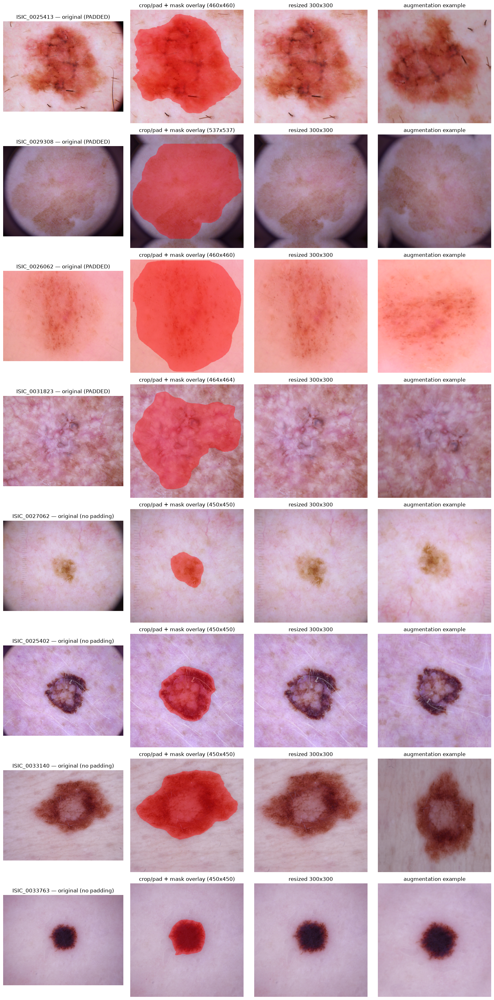


Check for each row:
  1. The red mask overlay shows the FULL lesion contained within the crop/pad region
  2. On PADDED rows, the padding (top/bottom) looks like plausible skin texture, not an obvious hard edge
  3. The augmentation example looks like a reasonable, still-recognisable variation


In [37]:
"""
08_08_validation_driver.txt
Resize/Crop — Validation Driver (Section 8).

Visual check across the full crop -> pad -> resize -> augment pipeline.
Deliberately samples SOME images from the padded subset (identified via
08_04's adaptive_crop_check.csv), not just random images, so the padding
itself is actually visible and checkable — plus some non-padded images
for baseline comparison.

Displays, per sampled image: original | crop/pad region with mask overlay
(confirms containment + padding style) | final 300x300 resize | one
random augmentation example.

Requires 05_00-05_07, 08_02-08_07, and 08_04's output CSV already available
(run 08_04 first).

This is a one-off diagnostic; the sample seed here is local to this
validation step only, not the pipeline's official random seed (Section 11).
"""

import random
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

VALIDATION_SEED = 123  # local to this validation step only
N_PADDED_SAMPLES = 4
N_UNPADDED_SAMPLES = 4


def find_image_path(image_id):
    for ext in (".jpg", ".jpeg", ".png"):
        candidate = IMAGES_DIR / f"{image_id}{ext}"
        if candidate.exists():
            return candidate
    raise FileNotFoundError(f"No image file found for {image_id}")


check_df = pd.read_csv(ARTIFACTS_DIR / "adaptive_crop_check.csv")
padded_ids = check_df.loc[check_df["needed_padding"], "image_id"].tolist()
unpadded_ids = check_df.loc[~check_df["needed_padding"], "image_id"].tolist()

random.seed(VALIDATION_SEED)
sample_ids = (
    random.sample(padded_ids, min(N_PADDED_SAMPLES, len(padded_ids)))
    + random.sample(unpadded_ids, min(N_UNPADDED_SAMPLES, len(unpadded_ids)))
)

print(f"Validating on {len(sample_ids)} images "
      f"({N_PADDED_SAMPLES} padded + {N_UNPADDED_SAMPLES} unpadded): {sample_ids}\n")

results = []
for image_id in sample_ids:
    img_path = find_image_path(image_id)
    image_bgr = cv2.imread(str(img_path))
    mask = load_lesion_mask(image_id)

    cropped_image, cropped_mask, plan = crop_pad_image_and_mask(image_bgr, mask)
    resized_image = resize_image(cropped_image)
    augmented = augment_image(resized_image)

    # Overlay mask on the crop/pad region for a visual containment check
    overlay = cropped_image.copy().astype(np.float32)
    red_layer = np.zeros_like(overlay)
    red_layer[..., 2] = 255  # BGR — red channel
    mask_bool = cropped_mask == 255
    overlay[mask_bool] = overlay[mask_bool] * 0.6 + red_layer[mask_bool] * 0.4
    overlay = overlay.astype(np.uint8)

    was_padded = (plan["pad_top"] + plan["pad_bottom"]) > 0

    results.append({
        "image_id": image_id,
        "was_padded": was_padded,
        "final_size": plan["final_size"],
        "original_rgb": cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB),
        "overlay_rgb": cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB),
        "resized_rgb": cv2.cvtColor(resized_image, cv2.COLOR_BGR2RGB),
        "augmented_rgb": cv2.cvtColor(augmented, cv2.COLOR_BGR2RGB),
    })

fig, axes = plt.subplots(len(results), 4, figsize=(16, 4 * len(results)))
for i, r in enumerate(results):
    tag = "PADDED" if r["was_padded"] else "no padding"
    axes[i, 0].imshow(r["original_rgb"])
    axes[i, 0].set_title(f"{r['image_id']} — original ({tag})")
    axes[i, 1].imshow(r["overlay_rgb"])
    axes[i, 1].set_title(f"crop/pad + mask overlay ({r['final_size']}x{r['final_size']})")
    axes[i, 2].imshow(r["resized_rgb"])
    axes[i, 2].set_title("resized 300x300")
    axes[i, 3].imshow(r["augmented_rgb"])
    axes[i, 3].set_title("augmentation example")
    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()

print("\nCheck for each row:")
print("  1. The red mask overlay shows the FULL lesion contained within the crop/pad region")
print("  2. On PADDED rows, the padding (top/bottom) looks like plausible skin texture, not an obvious hard edge")
print("  3. The augmentation example looks like a reasonable, still-recognisable variation")

##### Splitting

In [38]:
"""
09_00_lesion_consistency_check.txt
Lesion-Grouped Splitting — Lesion Consistency Check (Section 9).

For every unique lesion_id in HAM10000, checks whether dx (diagnosis) and
localization (anatomical site) are consistent across all images of that
lesion. This determines how a lesion's "representative" class and site
get defined for stratification — diagnosis should be a property of the
lesion itself (expect ~100% consistency), but site could plausibly differ
across a revisit (e.g. re-photographed at a slightly different angle/
description).

Also reports the images-per-lesion distribution — the first concrete
evidence of how much duplication the lesion-grouped split needs to handle.
"""

import pandas as pd

METADATA_PATH = BASE_DIR / "Resources" / "Dataset" / "HAM10000" / "HAM10000_metadata.tab"
metadata = pd.read_csv(METADATA_PATH, sep="\t")

print("=" * 60)
print("LESION CONSISTENCY CHECK — Phase 1 P2")
print("=" * 60)

n_images = len(metadata)
n_lesions = metadata["lesion_id"].nunique()
print(f"\nTotal images: {n_images}")
print(f"Total unique lesion_ids: {n_lesions}")
print(f"Mean images per lesion: {n_images / n_lesions:.2f}")

# --- Images-per-lesion distribution ---
images_per_lesion = metadata.groupby("lesion_id").size()
print("\n--- Images-per-lesion distribution ---")
dist = images_per_lesion.value_counts().sort_index()
print(dist.to_string())

# --- dx consistency per lesion ---
dx_per_lesion = metadata.groupby("lesion_id")["dx"].nunique()
dx_inconsistent = dx_per_lesion[dx_per_lesion > 1]
print("\n--- dx (diagnosis) consistency ---")
print(f"Lesions with a SINGLE consistent dx: {(dx_per_lesion == 1).sum()} "
      f"({(dx_per_lesion == 1).sum() / n_lesions * 100:.2f}%)")
print(f"Lesions with INCONSISTENT dx across images: {len(dx_inconsistent)}")

# --- localization consistency per lesion ---
loc_per_lesion = metadata.groupby("lesion_id")["localization"].nunique()
loc_inconsistent = loc_per_lesion[loc_per_lesion > 1]
print("\n--- localization (site) consistency ---")
print(f"Lesions with a SINGLE consistent site: {(loc_per_lesion == 1).sum()} "
      f"({(loc_per_lesion == 1).sum() / n_lesions * 100:.2f}%)")
print(f"Lesions with INCONSISTENT site across images: {len(loc_inconsistent)} "
      f"({len(loc_inconsistent) / n_lesions * 100:.2f}%)")


# --- Build lesion-level representative table ---
def most_common(series):
    return series.mode().iloc[0]  # first mode if tie


lesion_level = metadata.groupby("lesion_id").agg(
    n_images=("image_id", "count"),
    dx=("dx", most_common),
    dx_n_unique=("dx", "nunique"),
    localization=("localization", most_common),
    loc_n_unique=("localization", "nunique"),
).reset_index()

output_path = ARTIFACTS_DIR / "lesion_level_summary.csv"
lesion_level.to_csv(output_path, index=False)
print(f"\nLesion-level summary written to: {output_path}")

# --- Save any inconsistencies for direct inspection ---
if len(dx_inconsistent) > 0:
    dx_issue_ids = dx_inconsistent.index.tolist()
    dx_issue_rows = metadata[metadata["lesion_id"].isin(dx_issue_ids)].sort_values("lesion_id")
    dx_issue_path = ARTIFACTS_DIR / "dx_inconsistent_lesions.csv"
    dx_issue_rows.to_csv(dx_issue_path, index=False)
    print(f"\nWARNING: dx-inconsistent lesion details written to: {dx_issue_path}")
    print("This needs manual review before proceeding — dx should be a lesion property.")

if len(loc_inconsistent) > 0:
    loc_issue_ids = loc_inconsistent.index.tolist()
    loc_issue_rows = metadata[metadata["lesion_id"].isin(loc_issue_ids)].sort_values("lesion_id")
    loc_issue_path = ARTIFACTS_DIR / "localization_inconsistent_lesions.csv"
    loc_issue_rows.to_csv(loc_issue_path, index=False)
    print(f"\nSite-inconsistent lesion details written to: {loc_issue_path}")
    print("(Using the most common site per lesion as the representative value for stratification.)")

print("=" * 60)

LESION CONSISTENCY CHECK — Phase 1 P2

Total images: 10015
Total unique lesion_ids: 7470
Mean images per lesion: 1.34

--- Images-per-lesion distribution ---
1    5514
2    1423
3     490
4      34
5       5
6       4

--- dx (diagnosis) consistency ---
Lesions with a SINGLE consistent dx: 7470 (100.00%)
Lesions with INCONSISTENT dx across images: 0

--- localization (site) consistency ---
Lesions with a SINGLE consistent site: 7468 (99.97%)
Lesions with INCONSISTENT site across images: 2 (0.03%)

Lesion-level summary written to: T:\Thesis - Development\Resources\Artifacts\Phase 1 - P2\lesion_level_summary.csv

Site-inconsistent lesion details written to: T:\Thesis - Development\Resources\Artifacts\Phase 1 - P2\localization_inconsistent_lesions.csv
(Using the most common site per lesion as the representative value for stratification.)


In [39]:
"""
09_01_stratification_sparsity_check.txt
Lesion-Grouped Splitting — Stratification Sparsity Check (Section 9).

Using the lesion-level table from 09_00 (one row per unique lesion, with
its representative dx and localization), counts how many UNIQUE LESIONS
fall into each dx x localization combination — the actual unit that
StratifiedGroupKFold needs enough of, not image count.

Flags combinations too sparse to support:
  - A 5-fold CV split (needs >=5 lesions, so every fold can have at least 1)
  - Even a basic holdout/train split (needs >=2 lesions, so a single
    combination isn't forced entirely into one side or the other)

Requires 09_00 already run (reads lesion_level_summary.csv).
"""

import pandas as pd

MIN_LESIONS_FOR_5FOLD = 5
MIN_LESIONS_FOR_HOLDOUT_SPLIT = 2

lesion_level = pd.read_csv(ARTIFACTS_DIR / "lesion_level_summary.csv")

print("=" * 60)
print("STRATIFICATION SPARSITY CHECK — Phase 1 P2")
print("=" * 60)
print(f"Total unique lesions: {len(lesion_level)}\n")

# --- Cross-tab: unique lesions per dx x localization combination ---
crosstab = lesion_level.groupby(["dx", "localization"]).size().reset_index(name="n_lesions")
crosstab = crosstab.sort_values("n_lesions")

output_path = ARTIFACTS_DIR / "stratification_crosstab.csv"
crosstab.to_csv(output_path, index=False)
print(f"Full dx x localization lesion-count table written to: {output_path}")

total_combos = len(crosstab)
print(f"\nTotal dx x localization combinations present: {total_combos}")

# --- Severity buckets ---
n_1 = (crosstab["n_lesions"] == 1).sum()
n_2_4 = ((crosstab["n_lesions"] >= 2) & (crosstab["n_lesions"] < MIN_LESIONS_FOR_5FOLD)).sum()
n_5_9 = ((crosstab["n_lesions"] >= MIN_LESIONS_FOR_5FOLD) & (crosstab["n_lesions"] < 10)).sum()
n_10plus = (crosstab["n_lesions"] >= 10).sum()

print("\n--- Combination sparsity distribution ---")
print(f"Exactly 1 lesion (CANNOT split across holdout/train at all): {n_1}")
print(f"2-4 lesions (survives holdout split, but CANNOT support full 5-fold): {n_2_4}")
print(f"5-9 lesions (supports 5-fold, thin): {n_5_9}")
print(f"10+ lesions (comfortable): {n_10plus}")

# --- Flag and save the problematic combinations, with detail ---
sparse_combos = crosstab[crosstab["n_lesions"] < MIN_LESIONS_FOR_5FOLD]
print(f"\n--- Combinations below the 5-fold threshold (<{MIN_LESIONS_FOR_5FOLD} lesions) ---")
print(f"Total such combinations: {len(sparse_combos)} "
      f"(covering {sparse_combos['n_lesions'].sum()} lesions, "
      f"{sparse_combos['n_lesions'].sum() / len(lesion_level) * 100:.2f}% of all lesions)")

print("\n--- Breakdown by class (how many of ITS OWN site-combinations are sparse) ---")
by_class = sparse_combos.groupby("dx").agg(
    sparse_combo_count=("n_lesions", "count"),
    lesions_affected=("n_lesions", "sum"),
).reset_index()
print(by_class.to_string(index=False))

sparse_detail_path = ARTIFACTS_DIR / "sparse_stratification_combos.csv"
sparse_combos.to_csv(sparse_detail_path, index=False)
print(f"\nFull sparse-combination detail written to: {sparse_detail_path}")

# --- The most extreme cases: single-lesion combinations ---
single_lesion_combos = crosstab[crosstab["n_lesions"] == 1]
if len(single_lesion_combos) > 0:
    print(f"\n--- {len(single_lesion_combos)} combination(s) with EXACTLY 1 lesion (most severe case) ---")
    print(single_lesion_combos.to_string(index=False))

print("=" * 60)

STRATIFICATION SPARSITY CHECK — Phase 1 P2
Total unique lesions: 7470

Full dx x localization lesion-count table written to: T:\Thesis - Development\Resources\Artifacts\Phase 1 - P2\stratification_crosstab.csv

Total dx x localization combinations present: 81

--- Combination sparsity distribution ---
Exactly 1 lesion (CANNOT split across holdout/train at all): 8
2-4 lesions (survives holdout split, but CANNOT support full 5-fold): 11
5-9 lesions (supports 5-fold, thin): 10
10+ lesions (comfortable): 52

--- Combinations below the 5-fold threshold (<5 lesions) ---
Total such combinations: 19 (covering 37 lesions, 0.50% of all lesions)

--- Breakdown by class (how many of ITS OWN site-combinations are sparse) ---
   dx  sparse_combo_count  lesions_affected
akiec                   3                 6
  bcc                   3                 6
  bkl                   3                 6
   df                   4                 5
  mel                   1                 1
   nv         

In [16]:
"""
09_02_stratification_label.txt
Lesion-Grouped Splitting — Stratification Label Construction (Section 9).

Builds the combined dx + localization stratification label per lesion
(using each lesion's representative site from 09_00, i.e. the most common
site across that lesion's images), then propagates it down to every image
so each image inherits its lesion's label and group.

Also LOCKS THE RANDOM SEED for the first time — StratifiedGroupKFold
needs an actual value to produce a reproducible split, so this can't wait
for Section 11 (which verifies the seed is wired through everywhere, not
just declared — see Phase-1_Updated.md's catch of exactly this bug in the
teammate's original implementation).

Requires 09_00 already run (reads lesion_level_summary.csv).
"""

import pandas as pd

RANDOM_SEED = 42  # locked here, first use; verified end-to-end in Section 11

METADATA_PATH = BASE_DIR / "Resources" / "Dataset" / "HAM10000" / "HAM10000_metadata.tab"
metadata = pd.read_csv(METADATA_PATH, sep="\t")
lesion_level = pd.read_csv(ARTIFACTS_DIR / "lesion_level_summary.csv")

print("=" * 60)
print("STRATIFICATION LABEL CONSTRUCTION — Phase 1 P2")
print("=" * 60)
print(f"Random seed locked: {RANDOM_SEED}\n")

# --- Build combined label at the lesion level ---
lesion_level["strat_label"] = lesion_level["dx"] + "_" + lesion_level["localization"]
print(f"Unique combined dx+localization labels: {lesion_level['strat_label'].nunique()}")

# --- Propagate lesion-level dx/localization/strat_label down to every image ---
image_level = metadata.merge(
    lesion_level[["lesion_id", "dx", "localization", "strat_label"]],
    on="lesion_id", how="left", suffixes=("_original", "")
)

# Sanity check: every image should have matched successfully
unmatched = image_level["strat_label"].isna().sum()
print(f"\nImages successfully matched to a lesion-level label: {len(image_level) - unmatched} / {len(image_level)}")
if unmatched > 0:
    print(f"WARNING: {unmatched} image(s) failed to match — check lesion_id consistency.")

output_path = ARTIFACTS_DIR / "image_level_with_strat_label.csv"
image_level[["image_id", "lesion_id", "dx", "localization", "strat_label"]].to_csv(output_path, index=False)
print(f"\nImage-level table with stratification label written to: {output_path}")

print("=" * 60)

STRATIFICATION LABEL CONSTRUCTION — Phase 1 P2
Random seed locked: 42

Unique combined dx+localization labels: 81

Images successfully matched to a lesion-level label: 10015 / 10015

Image-level table with stratification label written to: T:\Thesis - Development\Resources\Artifacts\Phase 1 - P2\image_level_with_strat_label.csv


In [41]:
"""
09_03_holdout_split.txt
Lesion-Grouped Splitting — 15% Internal Holdout Carve-Out (Section 9).

Uses StratifiedGroupKFold(n_splits=7) to approximate a 15% holdout split
(1/7 ~= 14.3%), grouped by lesion_id so no lesion's images ever split
across holdout and the working pool. One fold becomes the holdout; the
remaining six folds' worth of lesions become the working pool that
Section 9's 5-fold CV gets built from next.

sklearn's StratifiedGroupKFold doesn't take a direct split-ratio argument,
so n_splits=7 is the standard way to approximate ~15% via this tool.

Requires 09_02 already run.
"""

import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold

image_level = pd.read_csv(ARTIFACTS_DIR / "image_level_with_strat_label.csv")

print("=" * 60)
print("15% INTERNAL HOLDOUT CARVE-OUT — Phase 1 P2")
print("=" * 60)

sgkf = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=RANDOM_SEED)

X = image_level["image_id"].values
y = image_level["strat_label"].values
groups = image_level["lesion_id"].values

splits = list(sgkf.split(X, y, groups))
working_pool_idx, holdout_idx = splits[0]  # take fold 0 as holdout

holdout_df = image_level.iloc[holdout_idx].copy()
working_pool_df = image_level.iloc[working_pool_idx].copy()

print(f"\nHoldout: {len(holdout_df)} images ({len(holdout_df) / len(image_level) * 100:.2f}%), "
      f"{holdout_df['lesion_id'].nunique()} unique lesions")
print(f"Working pool: {len(working_pool_df)} images ({len(working_pool_df) / len(image_level) * 100:.2f}%), "
      f"{working_pool_df['lesion_id'].nunique()} unique lesions")

# --- Sanity check: no lesion_id overlap between holdout and working pool ---
holdout_lesions = set(holdout_df["lesion_id"])
working_lesions = set(working_pool_df["lesion_id"])
overlap = holdout_lesions & working_lesions
print(f"\nLesion_id overlap between holdout and working pool: {len(overlap)} (expected: 0)")
if len(overlap) > 0:
    print("ERROR: lesion leakage detected between holdout and working pool!")

# --- Class distribution check ---
print("\n--- dx distribution: holdout vs working pool ---")
comparison = pd.DataFrame({
    "holdout_pct": (holdout_df["dx"].value_counts(normalize=True) * 100).round(2),
    "working_pool_pct": (working_pool_df["dx"].value_counts(normalize=True) * 100).round(2),
})
print(comparison.to_string())

# --- Save ---
holdout_path = ARTIFACTS_DIR / "holdout_split.csv"
working_pool_path = ARTIFACTS_DIR / "working_pool_split.csv"
holdout_df.to_csv(holdout_path, index=False)
working_pool_df.to_csv(working_pool_path, index=False)
print(f"\nHoldout saved to: {holdout_path}")
print(f"Working pool saved to: {working_pool_path}")

print("=" * 60)

15% INTERNAL HOLDOUT CARVE-OUT — Phase 1 P2


a:\anaconda3\envs\thesis-core\Lib\site-packages\sklearn\model_selection\_split.py:1036: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=7.
  warnings.warn(



Holdout: 1432 images (14.30%), 1067 unique lesions
Working pool: 8583 images (85.70%), 6403 unique lesions

Lesion_id overlap between holdout and working pool: 0 (expected: 0)

--- dx distribution: holdout vs working pool ---
       holdout_pct  working_pool_pct
dx                                  
nv           66.97             66.95
mel          11.10             11.11
bkl          11.03             10.96
bcc           5.31              5.10
akiec         3.21              3.27
vasc          1.33              1.43
df            1.05              1.17

Holdout saved to: T:\Thesis - Development\Resources\Artifacts\Phase 1 - P2\holdout_split.csv
Working pool saved to: T:\Thesis - Development\Resources\Artifacts\Phase 1 - P2\working_pool_split.csv


In [44]:
"""
09_04_cv_fold_split.txt
Lesion-Grouped Splitting — 5-Fold CV Split (Section 9).

Builds the stratified 5-fold CV split on the working pool (the 85% left
after 09_03's holdout carve-out), grouped by lesion_id, stratified by the
combined dx+localization label. Fold assignments are saved to disk, per
the checklist's explicit requirement.

Requires 09_03 already run.
"""

import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold

working_pool_df = pd.read_csv(ARTIFACTS_DIR / "working_pool_split.csv")

print("=" * 60)
print("5-FOLD CV SPLIT — Phase 1 P2")
print("=" * 60)

sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)

X = working_pool_df["image_id"].values
y = working_pool_df["strat_label"].values
groups = working_pool_df["lesion_id"].values

# NOTE: fixed from an earlier version that used pd.Series(..., dtype=int),
# which silently upcasts to float64 when constructed empty (NaN-filled)
# even with dtype=int requested. A plain numpy int array avoids this.
fold_assignments = np.empty(len(working_pool_df), dtype=int)
for fold_num, (train_idx, val_idx) in enumerate(sgkf.split(X, y, groups)):
    fold_assignments[val_idx] = fold_num

working_pool_df["cv_fold"] = fold_assignments

print("\n--- Images per fold ---")
print(working_pool_df["cv_fold"].value_counts().sort_index().to_string())

print("\n--- Unique lesions per fold ---")
print(working_pool_df.groupby("cv_fold")["lesion_id"].nunique().to_string())

print("\n--- dx distribution per fold (%) ---")
fold_dx_dist = pd.crosstab(working_pool_df["cv_fold"], working_pool_df["dx"], normalize="index") * 100
print(fold_dx_dist.round(2).to_string())

output_path = ARTIFACTS_DIR / "cv_fold_assignments.csv"
working_pool_df.to_csv(output_path, index=False)
print(f"\nFold assignments saved to: {output_path}")

print("=" * 60)

5-FOLD CV SPLIT — Phase 1 P2


a:\anaconda3\envs\thesis-core\Lib\site-packages\sklearn\model_selection\_split.py:1036: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(



--- Images per fold ---
cv_fold
0    1717
1    1716
2    1716
3    1718
4    1716

--- Unique lesions per fold ---
cv_fold
0    1284
1    1278
2    1276
3    1283
4    1282

--- dx distribution per fold (%) ---
dx       akiec   bcc    bkl    df    mel     nv  vasc
cv_fold                                              
0         3.15  5.18  11.07  1.22  11.12  66.92  1.34
1         3.38  4.95  10.90  1.17  11.19  67.02  1.40
2         3.32  5.24  10.84  1.11  11.01  66.96  1.52
3         3.32  5.06  11.00  1.05  11.00  66.94  1.63
4         3.21  5.07  11.01  1.28  11.25  66.90  1.28

Fold assignments saved to: T:\Thesis - Development\Resources\Artifacts\Phase 1 - P2\cv_fold_assignments.csv


In [45]:
"""
09_05_split_verification.txt
Lesion-Grouped Splitting — Full Split Verification (Section 9).

The real exit-gate check for this section:
  1. Confirms programmatically (not spot-checked) that no lesion_id appears
     in more than one of {holdout, fold 0, fold 1, ..., fold 4} across the
     entire dataset.
  2. Specifically reports how each of the 19 known-sparse dx x localization
     combinations (from 09_01) actually landed — which buckets got ZERO
     representation for each, precisely, rather than a vague "some
     imperfection exists".

Requires 09_00, 09_01, 09_03, 09_04 already run.
"""

import pandas as pd

holdout_df = pd.read_csv(ARTIFACTS_DIR / "holdout_split.csv")
cv_df = pd.read_csv(ARTIFACTS_DIR / "cv_fold_assignments.csv")
sparse_combos = pd.read_csv(ARTIFACTS_DIR / "sparse_stratification_combos.csv")

print("=" * 60)
print("FULL SPLIT VERIFICATION — Phase 1 P2")
print("=" * 60)

# --- 1. lesion_id uniqueness across ALL buckets (holdout + 5 folds) ---
holdout_df = holdout_df.copy()
holdout_df["bucket"] = "holdout"
cv_df = cv_df.copy()
cv_df["bucket"] = "fold_" + cv_df["cv_fold"].astype(int).astype(str)

all_df = pd.concat([holdout_df[["lesion_id", "bucket"]], cv_df[["lesion_id", "bucket"]]], ignore_index=True)

lesion_bucket_counts = all_df.groupby("lesion_id")["bucket"].nunique()
leaked_lesions = lesion_bucket_counts[lesion_bucket_counts > 1]

print(f"\nTotal unique lesions across all buckets: {all_df['lesion_id'].nunique()}")
print(f"Lesions appearing in MORE THAN ONE bucket: {len(leaked_lesions)} (expected: 0)")

if len(leaked_lesions) > 0:
    print("ERROR: Lesion leakage detected across buckets!")
    print(leaked_lesions)
else:
    print("CONFIRMED: every lesion appears in exactly one bucket (holdout or a single CV fold).")

# --- 2. Total image accounting ---
total_images = len(holdout_df) + len(cv_df)
print(f"\nTotal images across all buckets: {total_images} (expected: 10015)")

# --- 3. Sparse-combo landing report ---
print("\n" + "=" * 60)
print("SPARSE COMBINATION LANDING REPORT (19 combos from 09_01)")
print("=" * 60)

full_df = pd.concat([
    holdout_df[["dx", "localization", "bucket"]],
    cv_df[["dx", "localization", "bucket"]],
], ignore_index=True)

buckets = ["holdout"] + [f"fold_{i}" for i in range(5)]

landing_rows = []
for _, row in sparse_combos.iterrows():
    dx_val, loc_val = row["dx"], row["localization"]
    subset = full_df[(full_df["dx"] == dx_val) & (full_df["localization"] == loc_val)]
    bucket_counts = subset["bucket"].value_counts()

    zero_buckets = [b for b in buckets if bucket_counts.get(b, 0) == 0]
    landing_rows.append({
        "dx": dx_val, "localization": loc_val, "total_lesions": row["n_lesions"],
        **{b: bucket_counts.get(b, 0) for b in buckets},
        "buckets_with_zero": ", ".join(zero_buckets) if zero_buckets else "none",
    })

landing_df = pd.DataFrame(landing_rows)
print(landing_df.to_string(index=False))

landing_path = ARTIFACTS_DIR / "sparse_combo_landing_report.csv"
landing_df.to_csv(landing_path, index=False)
print(f"\nFull landing report saved to: {landing_path}")

n_with_gaps = (landing_df["buckets_with_zero"] != "none").sum()
print(f"\n{n_with_gaps} of {len(landing_df)} sparse combinations have at least one "
      f"bucket with zero representation for that specific class+site pair.")
print("Class-level (dx) representation is unaffected regardless — this only concerns")
print("the finer class+site combination for these specific 19 pairs (0.50% of lesions).")

print("=" * 60)

FULL SPLIT VERIFICATION — Phase 1 P2

Total unique lesions across all buckets: 7470
Lesions appearing in MORE THAN ONE bucket: 0 (expected: 0)
CONFIRMED: every lesion appears in exactly one bucket (holdout or a single CV fold).

Total images across all buckets: 10015 (expected: 10015)

SPARSE COMBINATION LANDING REPORT (19 combos from 09_01)
   dx localization  total_lesions  holdout  fold_0  fold_1  fold_2  fold_3  fold_4                       buckets_with_zero
akiec        trunk              1        0       0       0       1       0       0 holdout, fold_0, fold_1, fold_3, fold_4
  bkl         foot              1        0       1       0       0       0       0 holdout, fold_1, fold_2, fold_3, fold_4
  bkl      genital              1        2       0       0       0       0       0  fold_0, fold_1, fold_2, fold_3, fold_4
  bcc         hand              1        0       0       0       0       0       2 holdout, fold_0, fold_1, fold_2, fold_3
  mel         hand              1        

##### Class Imbalance Handling

In [17]:
"""
10_00_effective_number_function.txt
Class Imbalance Handling — Effective-Number Weight Function (Section 10).

Implements the effective-number-of-samples formula (Cui et al., 2019):
  E_n = (1 - beta^n) / (1 - beta)
Each class's loss weight is proportional to 1/E_n, normalised across
classes so weights sum to the number of classes (mean weight = 1.0) --
keeps overall loss magnitude stable rather than shifting just from
adding weighting.
"""

import numpy as np


def compute_effective_number_weights(class_counts, beta):
    """
    class_counts: dict {class_name: count} or pandas Series
    beta: float in [0.99, 0.9999] per the locked methodology range

    Returns: dict {class_name: weight}, normalised so weights sum to
             len(class_counts) (mean weight = 1.0)
    """
    classes = list(class_counts.keys()) if isinstance(class_counts, dict) else class_counts.index.tolist()
    counts = np.array([class_counts[c] for c in classes], dtype=np.float64)

    effective_num = (1.0 - np.power(beta, counts)) / (1.0 - beta)
    raw_weights = 1.0 / effective_num

    # Normalise so weights sum to n_classes (mean weight = 1.0)
    normalized_weights = raw_weights / raw_weights.sum() * len(classes)

    return dict(zip(classes, normalized_weights))

In [18]:
"""
10_01_per_fold_training_counts.txt
Class Imbalance Handling — Per-Fold Training Class Counts (Section 10).

For each of the 5 CV folds, computes what that fold's TRAINING set class
counts actually are — i.e. for fold i, training = the other 4 folds
combined, NOT fold i itself and NOT the global dataset. This is the exact
requirement flagged in Section 3.4: "computed from the training fold's
own class counts, never global/validation/holdout counts" — reusing one
global count for all 5 folds would be a subtle leakage bug.

Requires cv_fold_assignments.csv (Section 9) already on disk.
"""

import pandas as pd

cv_df = pd.read_csv(ARTIFACTS_DIR / "cv_fold_assignments.csv")

print("=" * 60)
print("PER-FOLD TRAINING CLASS COUNTS — Phase 1 P2")
print("=" * 60)

CLASSES = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]

per_fold_counts = {}
for fold_num in sorted(cv_df["cv_fold"].unique()):
    # Training data for this fold = every OTHER fold combined
    train_subset = cv_df[cv_df["cv_fold"] != fold_num]
    counts = train_subset["dx"].value_counts().reindex(CLASSES, fill_value=0)
    per_fold_counts[fold_num] = counts

    print(f"\n--- Fold {fold_num} training set (folds != {fold_num}) ---")
    print(f"Total training images: {len(train_subset)}")
    print(counts.to_string())

# --- Save as a single table for reuse ---
counts_table = pd.DataFrame(per_fold_counts)
counts_table.index.name = "dx"
output_path = ARTIFACTS_DIR / "per_fold_training_class_counts.csv"
counts_table.to_csv(output_path)
print(f"\nPer-fold training class counts written to: {output_path}")

print("=" * 60)

PER-FOLD TRAINING CLASS COUNTS — Phase 1 P2

--- Fold 0 training set (folds != 0) ---
Total training images: 6866
dx
akiec     227
bcc       349
bkl       751
df         79
mel       763
nv       4597
vasc      100

--- Fold 1 training set (folds != 1) ---
Total training images: 6867
dx
akiec     223
bcc       353
bkl       754
df         80
mel       762
nv       4596
vasc       99

--- Fold 2 training set (folds != 2) ---
Total training images: 6867
dx
akiec     224
bcc       348
bkl       755
df         81
mel       765
nv       4597
vasc       97

--- Fold 3 training set (folds != 3) ---
Total training images: 6865
dx
akiec     224
bcc       351
bkl       752
df         82
mel       765
nv       4596
vasc       95

--- Fold 4 training set (folds != 4) ---
Total training images: 6867
dx
akiec     226
bcc       351
bkl       752
df         78
mel       761
nv       4598
vasc      101

Per-fold training class counts written to: T:\Thesis - Development\Resources\Artifacts\Phase 1 - P2\

In [19]:
"""
10_02_beta_comparison.txt
Class Imbalance Handling — Beta Comparison (Section 10).

Computes effective-number class weights across candidate beta values,
using fold 0's actual training class counts (representative — per-fold
counts barely differ, confirmed in Section 9). Compares the resulting
weight ratio (max/min) across candidates to make the aggressiveness
trade-off legible before choosing — same approach as the clip_limit
comparison in Section 6.

Requires 10_00 and 10_01 already run.
"""

import pandas as pd

BETA_CANDIDATES = [0.99, 0.999, 0.9999]

counts_table = pd.read_csv(ARTIFACTS_DIR / "per_fold_training_class_counts.csv", index_col="dx")
fold_0_counts = counts_table["0"].to_dict()  # representative fold

print("=" * 60)
print("BETA COMPARISON — Phase 1 P2")
print("=" * 60)
print("Using fold 0's training class counts (representative across folds):")
print(pd.Series(fold_0_counts).to_string())

comparison_rows = []
for beta in BETA_CANDIDATES:
    weights = compute_effective_number_weights(fold_0_counts, beta)
    row = {"beta": beta, **weights}
    row["weight_ratio_max_min"] = max(weights.values()) / min(weights.values())
    comparison_rows.append(row)

comparison_df = pd.DataFrame(comparison_rows).set_index("beta")
print("\n--- Class weights by candidate beta (mean weight = 1.0) ---")
print(comparison_df.round(3).to_string())

output_path = ARTIFACTS_DIR / "beta_comparison.csv"
comparison_df.to_csv(output_path)
print(f"\nComparison written to: {output_path}")

print("\nInterpretation:")
print("  - Higher beta = more aggressive correction = larger gap between DF's weight and NV's weight")
print("  - weight_ratio_max_min shows how extreme that gap gets, in one number per candidate")
print("=" * 60)

BETA COMPARISON — Phase 1 P2
Using fold 0's training class counts (representative across folds):
akiec     227
bcc       349
bkl       751
df         79
mel       763
nv       4597
vasc      100

--- Class weights by candidate beta (mean weight = 1.0) ---
        akiec    bcc    bkl     df    mel     nv   vasc  weight_ratio_max_min
beta                                                                         
0.9900  0.912  0.844  0.819  1.494  0.819  0.819  1.292                 1.825
0.9990  0.937  0.646  0.361  2.506  0.357  0.192  2.000                13.026
0.9999  0.941  0.616  0.292  2.684  0.287  0.057  2.123                46.833

Comparison written to: T:\Thesis - Development\Resources\Artifacts\Phase 1 - P2\beta_comparison.csv

Interpretation:
  - Higher beta = more aggressive correction = larger gap between DF's weight and NV's weight
  - weight_ratio_max_min shows how extreme that gap gets, in one number per candidate


In [20]:
"""
10_03_final_class_weights.txt
Class Imbalance Handling — Final Class Weights (Section 10).

Computes the LOCKED effective-number class weights (beta=0.999) for each
of the 5 CV folds, using each fold's own training-set class counts
(10_01) — never global counts. Includes an explicit by-hand verification
of DF's weight against the raw formula, per the checklist's requirement.

Requires 10_00 and 10_01 already run.
"""

import pandas as pd

BETA_FINAL = 0.999  # LOCKED — chosen via comparison across 0.99/0.999/0.9999
                     # on real per-fold training counts (10_02). Balances
                     # correcting NV vs medium-class under-weighting (seen
                     # at 0.99) against compounding the balanced sampler's
                     # rare-class memorisation risk (R2) at 0.9999.

counts_table = pd.read_csv(ARTIFACTS_DIR / "per_fold_training_class_counts.csv", index_col="dx")

print("=" * 60)
print("FINAL CLASS WEIGHTS — Phase 1 P2")
print(f"Locked beta = {BETA_FINAL}")
print("=" * 60)

per_fold_weights = {}
for fold_col in counts_table.columns:
    fold_counts = counts_table[fold_col].to_dict()
    weights = compute_effective_number_weights(fold_counts, BETA_FINAL)
    per_fold_weights[fold_col] = weights

    print(f"\n--- Fold {fold_col} training weights ---")
    print(pd.Series(weights).round(4).to_string())

weights_df = pd.DataFrame(per_fold_weights)
weights_df.index.name = "dx"
output_path = ARTIFACTS_DIR / "final_class_weights_per_fold.csv"
weights_df.to_csv(output_path)
print(f"\nFinal per-fold class weights written to: {output_path}")

# --- By-hand verification for DF (fold 0), per the checklist's requirement ---
print("\n" + "=" * 60)
print("BY-HAND VERIFICATION — DF, Fold 0")
print("=" * 60)

df_count_fold0 = counts_table.loc["df", "0"]
print(f"DF count in fold 0's training set: {df_count_fold0}")

effective_num_manual = (1 - BETA_FINAL ** df_count_fold0) / (1 - BETA_FINAL)
raw_weight_manual = 1 / effective_num_manual
print("\nManual calculation:")
print(f"  E_n = (1 - {BETA_FINAL}^{df_count_fold0}) / (1 - {BETA_FINAL})")
print(f"  E_n = (1 - {BETA_FINAL ** df_count_fold0:.6f}) / {1 - BETA_FINAL}")
print(f"  E_n = {effective_num_manual:.4f}")
print(f"  raw weight (1/E_n) = {raw_weight_manual:.4f}")

function_weight = compute_effective_number_weights(counts_table["0"].to_dict(), BETA_FINAL)["df"]
print(f"\nFunction output (normalised, mean=1.0): {function_weight:.4f}")

# Cross-check: does manual raw weight, when normalised the same way, match?
all_raw_weights_fold0 = {
    c: 1 / ((1 - BETA_FINAL ** counts_table.loc[c, "0"]) / (1 - BETA_FINAL))
    for c in counts_table.index
}
manual_normalized = raw_weight_manual / sum(all_raw_weights_fold0.values()) * len(all_raw_weights_fold0)
print(f"Manual raw weight, normalised the same way as the function: {manual_normalized:.4f}")

match = abs(manual_normalized - function_weight) < 1e-6
print(f"\nMatch: {match}")
if not match:
    print("WARNING: manual and function-computed weights disagree — investigate before proceeding.")

print("=" * 60)

FINAL CLASS WEIGHTS — Phase 1 P2
Locked beta = 0.999

--- Fold 0 training weights ---
akiec    0.9375
bcc      0.6462
bkl      0.3605
df       2.5062
mel      0.3567
nv       0.1924
vasc     2.0005

--- Fold 1 training weights ---
akiec    0.9528
bcc      0.6404
bkl      0.3597
df       2.4770
mel      0.3572
nv       0.1925
vasc     2.0205

--- Fold 2 training weights ---
akiec    0.9473
bcc      0.6468
bkl      0.3587
df       2.4432
mel      0.3556
nv       0.1921
vasc     2.0563

--- Fold 3 training weights ---
akiec    0.9460
bcc      0.6414
bkl      0.3592
df       2.4115
mel      0.3551
nv       0.1919
vasc     2.0949

--- Fold 4 training weights ---
akiec    0.9394
bcc      0.6420
bkl      0.3595
df       2.5324
mel      0.3567
nv       0.1920
vasc     1.9780

Final per-fold class weights written to: T:\Thesis - Development\Resources\Artifacts\Phase 1 - P2\final_class_weights_per_fold.csv

BY-HAND VERIFICATION — DF, Fold 0
DF count in fold 0's training set: 79

Manual calculati

In [24]:
"""
10_04_balanced_sampler.txt
Class Imbalance Handling — Balanced Mini-Batch Sampler (Section 10).

Builds a WeightedRandomSampler for balanced mini-batch sampling — a
GENUINELY SEPARATE mechanism from the effective-number loss weights
(10_03). Per Section 3.4/Watch-Out-For: a bug can silently disable one
while the other still looks correct, so these are built, and will be
verified, independently.

Uses simple inverse class-frequency weighting per sample (not the
effective-number formula — that's specific to loss weighting; the
sampler's job is just to make every class equally likely to be drawn
per batch, which plain inverse frequency achieves directly).
"""

import torch
from torch.utils.data import WeightedRandomSampler


def build_balanced_sampler(labels, seed=RANDOM_SEED):
    """
    labels: array-like of class labels (strings or ints), one per training
            sample, in dataset order.
    seed: seeds the sampler's own torch.Generator, so draw order is
          reproducible across runs — previously unseeded (Section 11 gap;
          fixed here with a dedicated Generator, independent of whatever
          the global torch/numpy random state happens to be).

    Returns: torch.utils.data.WeightedRandomSampler, with replacement,
             num_samples = len(labels) (one full "epoch" length).
    """
    import pandas as pd

    labels_series = pd.Series(labels)
    class_counts = labels_series.value_counts()

    # Inverse frequency — rarer classes get a larger per-sample weight
    class_weight_map = 1.0 / class_counts
    sample_weights = labels_series.map(class_weight_map).values

    generator = torch.Generator()
    generator.manual_seed(seed)

    sampler = WeightedRandomSampler(
        weights=torch.as_tensor(sample_weights, dtype=torch.double),
        num_samples=len(labels_series),
        replacement=True,
        generator=generator,
    )
    return sampler

In [22]:
"""
10_05_dataloader_diagnostic.txt
Class Imbalance Handling — DataLoader Diagnostic (Section 10).

Confirms the balanced sampler (10_04) is genuinely active AT THE
DATA-LOADER LEVEL — not inferred from the loss weights looking correct.
A real DataLoader wired with the sampler, run over several hundred
batches, empirical class frequency tallied against both the intended
balanced target (~14.29% each) and HAM10000's natural ~67% NV skew.

Uses fold 0's REAL training labels (not synthetic/random) — matches
Section 3.4's requirement to verify against actual training-fold data.

Requires 10_04 already run.
"""

import pandas as pd
from torch.utils.data import Dataset, DataLoader

N_DIAGNOSTIC_BATCHES = 300
BATCH_SIZE = 32

cv_df = pd.read_csv(ARTIFACTS_DIR / "cv_fold_assignments.csv")
fold0_train_labels = cv_df.loc[cv_df["cv_fold"] != 0, "dx"].reset_index(drop=True)

print("=" * 60)
print("DATALOADER DIAGNOSTIC — Balanced Sampler — Phase 1 P2")
print("=" * 60)
print(f"Using fold 0's real training labels: {len(fold0_train_labels)} samples")

print("\n--- Natural (unweighted) class distribution in this training set ---")
natural_dist = (fold0_train_labels.value_counts(normalize=True) * 100).round(2)
print(natural_dist.to_string())


class LabelOnlyDataset(Dataset):
    """Minimal dataset — labels only, no image loading, for a fast diagnostic."""
    def __init__(self, labels):
        self.labels = labels.reset_index(drop=True)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return idx, self.labels.iloc[idx]


dataset = LabelOnlyDataset(fold0_train_labels)
sampler = build_balanced_sampler(fold0_train_labels)
loader = DataLoader(dataset, batch_size=BATCH_SIZE, sampler=sampler)

print(f"\nRunning {N_DIAGNOSTIC_BATCHES} batches (batch_size={BATCH_SIZE}) through a real DataLoader...")

observed_labels = []
for batch_num, (idx_batch, label_batch) in enumerate(loader):
    observed_labels.extend(label_batch)
    if batch_num + 1 >= N_DIAGNOSTIC_BATCHES:
        break

print(f"Total samples drawn: {len(observed_labels)}")

observed_series = pd.Series(observed_labels)
empirical_dist = (observed_series.value_counts(normalize=True) * 100).round(2)

n_classes = fold0_train_labels.nunique()
ideal_target = 100 / n_classes

comparison = pd.DataFrame({
    "natural_pct": natural_dist,
    "empirical_sampled_pct": empirical_dist,
    "ideal_balanced_target_pct": ideal_target,
})
comparison = comparison.reindex(sorted(comparison.index))

print("\n--- Comparison: natural vs. empirically sampled vs. ideal balanced target ---")
print(comparison.to_string())

max_deviation = (comparison["empirical_sampled_pct"] - ideal_target).abs().max()
print(f"\nMax deviation from ideal balanced target: {max_deviation:.2f} percentage points")

if max_deviation < 3.0:
    print("CONFIRMED: sampler is active at the data-loader level — empirical frequency")
    print("tracks the intended balanced target, not the natural ~67% NV skew.")
else:
    print("WARNING: empirical distribution deviates meaningfully from the balanced target —")
    print("investigate whether the sampler is genuinely wired into the DataLoader correctly.")

output_path = ARTIFACTS_DIR / "sampler_diagnostic_comparison.csv"
comparison.to_csv(output_path)
print(f"\nComparison written to: {output_path}")

print("=" * 60)

DATALOADER DIAGNOSTIC — Balanced Sampler — Phase 1 P2
Using fold 0's real training labels: 6866 samples

--- Natural (unweighted) class distribution in this training set ---
dx
nv       66.95
mel      11.11
bkl      10.94
bcc       5.08
akiec     3.31
vasc      1.46
df        1.15

Running 300 batches (batch_size=32) through a real DataLoader...


C:\Users\primu\AppData\Local\Temp\ipykernel_10100\4057522005.py:39: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:219.)
  weights=torch.as_tensor(sample_weights, dtype=torch.double),


Total samples drawn: 6866

--- Comparison: natural vs. empirically sampled vs. ideal balanced target ---
       natural_pct  empirical_sampled_pct  ideal_balanced_target_pct
akiec         3.31                  14.32                  14.285714
bcc           5.08                  14.43                  14.285714
bkl          10.94                  13.73                  14.285714
df            1.15                  14.29                  14.285714
mel          11.11                  14.38                  14.285714
nv           66.95                  14.38                  14.285714
vasc          1.46                  14.48                  14.285714

Max deviation from ideal balanced target: 0.56 percentage points
CONFIRMED: sampler is active at the data-loader level — empirical frequency
tracks the intended balanced target, not the natural ~67% NV skew.

Comparison written to: T:\Thesis - Development\Resources\Artifacts\Phase 1 - P2\sampler_diagnostic_comparison.csv


##### Reproducibility

In [23]:
"""
11_00_master_seed_function.txt
Reproducibility — Master Seed Function (Section 11).

Single function to seed every source of randomness this pipeline touches:
Python's own random module, numpy, and both PyTorch's CPU and CUDA RNGs.
Also sets cuDNN's deterministic flags — these do nothing for Phase 1
itself (no GPU training happens here), but Phase 2/3 will need them, so
built once now rather than rebuilt later.

Call this ONCE at the start of any script that needs reproducible
randomness (training runs, reproducibility verification, etc.) — not
inside a loop, not per-batch.
"""

import random
import numpy as np
import torch


def set_all_seeds(seed=RANDOM_SEED):
    """
    Seeds Python's random, numpy, and PyTorch (CPU + all CUDA devices).
    Also enables cuDNN deterministic mode and disables its benchmark mode
    (benchmark mode picks algorithms based on runtime timing, which is
    itself a source of non-determinism — needed for Phase 2/3, harmless
    here).
    """
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    print(f"All random seeds set to {seed} (Python random, numpy, PyTorch CPU+CUDA).")
    print("cuDNN deterministic mode enabled, benchmark mode disabled.")

In [25]:
"""
11_01_reproducibility_verification.txt
Reproducibility — Verification (Section 11).

Proves, empirically, that both known randomness gaps are now closed:
  - 08_07's augment_image() (uses np.random directly — needs the global
    seed set via set_all_seeds() before each run)
  - 10_04's build_balanced_sampler() (now has its own explicit seed
    parameter, independent of global random state)

Seed the same way, run twice, confirm identical output both times —
augmentation compared pixel-for-pixel, sampler compared draw-for-draw.

Requires 11_00, 05_00-05_07, 08_07 (augment_image), 10_04 (updated
build_balanced_sampler) already defined.
"""

import cv2
import numpy as np
import pandas as pd

TEST_IMAGE_ID = "ISIC_0024306"  # fixed, arbitrary — first image in the dataset


def find_image_path(image_id):
    for ext in (".jpg", ".jpeg", ".png"):
        candidate = IMAGES_DIR / f"{image_id}{ext}"
        if candidate.exists():
            return candidate
    raise FileNotFoundError(f"No image file found for {image_id}")


print("=" * 60)
print("REPRODUCIBILITY VERIFICATION — Phase 1 P2")
print("=" * 60)

# --- Load a fixed test image ---
img_path = find_image_path(TEST_IMAGE_ID)
test_image = cv2.imread(str(img_path))
test_image = cv2.resize(test_image, (RESIZE_TARGET, RESIZE_TARGET))  # match real pipeline size

# --- Run 1 ---
set_all_seeds(RANDOM_SEED)
augmented_run1 = augment_image(test_image)

cv_df = pd.read_csv(ARTIFACTS_DIR / "cv_fold_assignments.csv")
fold0_train_labels = cv_df.loc[cv_df["cv_fold"] != 0, "dx"].reset_index(drop=True)
sampler_run1 = build_balanced_sampler(fold0_train_labels, seed=RANDOM_SEED)
draws_run1 = list(sampler_run1)[:50]  # first 50 draws

# --- Run 2 (reset seed, repeat identically) ---
set_all_seeds(RANDOM_SEED)
augmented_run2 = augment_image(test_image)

sampler_run2 = build_balanced_sampler(fold0_train_labels, seed=RANDOM_SEED)
draws_run2 = list(sampler_run2)[:50]

# --- Compare ---
print("\n--- Augmentation reproducibility ---")
augmentation_match = np.array_equal(augmented_run1, augmented_run2)
print(f"Run 1 vs Run 2, pixel-for-pixel identical: {augmentation_match}")
if not augmentation_match:
    diff = np.abs(augmented_run1.astype(int) - augmented_run2.astype(int))
    print(f"WARNING: max pixel difference = {diff.max()}")

print("\n--- Sampler reproducibility ---")
sampler_match = draws_run1 == draws_run2
print(f"First 50 draws, Run 1 vs Run 2, identical sequence: {sampler_match}")
if not sampler_match:
    print(f"Run 1 first 10 draws: {draws_run1[:10]}")
    print(f"Run 2 first 10 draws: {draws_run2[:10]}")

print("\n" + "=" * 60)
if augmentation_match and sampler_match:
    print("CONFIRMED: both augmentation and sampler are fully reproducible")
    print("given the same seed. Section 11's core requirement is verified.")
else:
    print("WARNING: one or more components are NOT reproducible — investigate before Phase 2.")
print("=" * 60)

REPRODUCIBILITY VERIFICATION — Phase 1 P2
All random seeds set to 42 (Python random, numpy, PyTorch CPU+CUDA).
cuDNN deterministic mode enabled, benchmark mode disabled.
All random seeds set to 42 (Python random, numpy, PyTorch CPU+CUDA).
cuDNN deterministic mode enabled, benchmark mode disabled.

--- Augmentation reproducibility ---
Run 1 vs Run 2, pixel-for-pixel identical: True

--- Sampler reproducibility ---
First 50 draws, Run 1 vs Run 2, identical sequence: True

CONFIRMED: both augmentation and sampler are fully reproducible
given the same seed. Section 11's core requirement is verified.


In [26]:
"""
11_02_environment_fingerprint.txt
Reproducibility — Environment Fingerprint (Section 11).

Consolidates exact library/hardware versions into one saved reference,
for the methodology write-up's reproducibility disclosure (Section 4.6:
"exact framework/library/CUDA/Python versions documented; hardware
specification recorded").
"""

import sys
import platform
import torch
import torchvision
import cv2
import numpy as np
import pandas as pd
import sklearn

print("=" * 60)
print("ENVIRONMENT FINGERPRINT — Phase 1 P2")
print("=" * 60)

fingerprint_lines = [
    f"Python version:        {sys.version}",
    f"Platform:              {platform.platform()}",
    f"PyTorch version:       {torch.__version__}",
    f"Torchvision version:   {torchvision.__version__}",
    f"CUDA build version:    {torch.version.cuda}",
    f"CUDA available:        {torch.cuda.is_available()}",
]

if torch.cuda.is_available():
    fingerprint_lines += [
        f"GPU device:            {torch.cuda.get_device_name(0)}",
        f"Compute capability:    {torch.cuda.get_device_capability(0)}",
    ]

fingerprint_lines += [
    f"OpenCV version:        {cv2.__version__}",
    f"NumPy version:         {np.__version__}",
    f"Pandas version:        {pd.__version__}",
    f"scikit-learn version:  {sklearn.__version__}",
    f"Random seed (locked):  {RANDOM_SEED}",
]

for line in fingerprint_lines:
    print(line)

output_path = ARTIFACTS_DIR / "environment_fingerprint.txt"
with open(output_path, "w", encoding="utf-8") as f:
    f.write("\n".join(fingerprint_lines))

print(f"\nEnvironment fingerprint written to: {output_path}")
print("=" * 60)

ENVIRONMENT FINGERPRINT — Phase 1 P2
Python version:        3.11.15 | packaged by Anaconda, Inc. | (main, Jun 11 2026, 15:12:53) [MSC v.1942 64 bit (AMD64)]
Platform:              Windows-10-10.0.26200-SP0
PyTorch version:       2.11.0+cu128
Torchvision version:   0.26.0+cu128
CUDA build version:    12.8
CUDA available:        True
GPU device:            NVIDIA GeForce RTX 5060 Ti
Compute capability:    (12, 0)
OpenCV version:        5.0.0
NumPy version:         2.4.6
Pandas version:        3.0.5
scikit-learn version:  1.9.0
Random seed (locked):  42

Environment fingerprint written to: T:\Thesis - Development\Resources\Artifacts\Phase 1 - P2\environment_fingerprint.txt


##### Final Output

In [27]:
"""
12_00_combined_pipeline_config.txt
Combined Single-Pass Pipeline — Configuration (Section 12).
"""

FINAL_OUTPUT_DIR = ARTIFACTS_DIR / "Final Output Phase 1"
FINAL_IMAGES_DIR = FINAL_OUTPUT_DIR / "images"
FINAL_MASKS_DIR = FINAL_OUTPUT_DIR / "masks"

FINAL_IMAGES_DIR.mkdir(parents=True, exist_ok=True)
FINAL_MASKS_DIR.mkdir(parents=True, exist_ok=True)

JPEG_QUALITY = 95  # single save point, no repeated re-encoding -- high quality is safe

MANIFEST_PATH = ARTIFACTS_DIR / "final_pipeline_manifest.csv"

print("Combined pipeline config loaded.")
print(f"  Final images: {FINAL_IMAGES_DIR}")
print(f"  Final masks:  {FINAL_MASKS_DIR}")
print(f"  JPEG quality: {JPEG_QUALITY}")
print(f"  Manifest:     {MANIFEST_PATH}")

Combined pipeline config loaded.
  Final images: T:\Thesis - Development\Resources\Artifacts\Phase 1 - P2\Final Output Phase 1\images
  Final masks:  T:\Thesis - Development\Resources\Artifacts\Phase 1 - P2\Final Output Phase 1\masks
  JPEG quality: 95
  Manifest:     T:\Thesis - Development\Resources\Artifacts\Phase 1 - P2\final_pipeline_manifest.csv


In [28]:
"""
12_02_full_dataset_run.txt
Combined Single-Pass Pipeline — Full Dataset Run (Section 12).

Runs the full deterministic preprocessing chain, in memory, per image,
across all 10,015 HAM10000 images — the only place these processed
images and masks actually get written to disk:

  hair removal (Section 5, reusing persisted hair masks)
  -> CLAHE, clip_limit=1.5 (Section 6, locked)
  -> adaptive crop/pad (Section 8, image + mask transformed identically)
  -> resize to 300x300 (Section 8)
  -> save image (.jpg) + mask (.png)

Augmentation and normalisation are correctly EXCLUDED from this pass —
both are training-time-only operations (Section 8/11).

RESUMABLE: checks the manifest CSV for image_ids already completed and
skips them; each row is written and flushed immediately, so an
interruption only loses the one image in progress.

Requires 05_00-05_07, 06_00-06_01, 08_02-08_03, 08_05, 12_00 already
defined.
"""

import csv
import cv2
import pandas as pd
from tqdm import tqdm

METADATA_PATH = BASE_DIR / "Resources" / "Dataset" / "HAM10000" / "HAM10000_metadata.tab"
FIELDNAMES = ["image_id", "dx", "final_size", "was_padded"]

metadata = pd.read_csv(METADATA_PATH, sep="\t")
dx_lookup = dict(zip(metadata["image_id"], metadata["dx"]))


def find_image_path(image_id):
    for ext in (".jpg", ".jpeg", ".png"):
        candidate = IMAGES_DIR / f"{image_id}{ext}"
        if candidate.exists():
            return candidate
    raise FileNotFoundError(f"No image file found for {image_id}")


def load_hair_mask(image_id):
    mask_path = HAIR_MASKS_DIR / f"{image_id}_hairmask.png"
    mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
    if mask is None:
        raise ValueError(f"Hair mask failed to load: {mask_path}")
    return mask


# --- Resume logic ---
if MANIFEST_PATH.exists():
    done_df = pd.read_csv(MANIFEST_PATH)
    completed_ids = set(done_df["image_id"])
    print(f"Resuming — {len(completed_ids)} image(s) already completed, will be skipped.")
else:
    completed_ids = set()
    with open(MANIFEST_PATH, "w", newline="") as f:
        csv.DictWriter(f, fieldnames=FIELDNAMES).writeheader()
    print("Starting fresh run.")

all_image_ids = sorted(
    f.stem for f in IMAGES_DIR.iterdir() if f.suffix.lower() in (".jpg", ".jpeg", ".png")
)
remaining_ids = [i for i in all_image_ids if i not in completed_ids]

print("=" * 60)
print("COMBINED PIPELINE — FULL DATASET RUN — Phase 1 P2")
print("=" * 60)
print(f"Total images: {len(all_image_ids)} | Already done: {len(completed_ids)} | Remaining: {len(remaining_ids)}\n")

with open(MANIFEST_PATH, "a", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=FIELDNAMES)

    for image_id in tqdm(remaining_ids, desc="Combined pipeline"):
        img_path = find_image_path(image_id)
        image_bgr = cv2.imread(str(img_path))
        lesion_mask = load_lesion_mask(image_id, target_shape=image_bgr.shape[:2])

        # 1. Hair removal — reuse Section 5's persisted hair masks
        hair_mask = load_hair_mask(image_id)
        hair_removed = remove_hair(image_bgr, hair_mask)

        # 2. CLAHE (clip_limit=1.5, locked)
        enhanced = apply_clahe(hair_removed)

        # 3. Adaptive crop/pad — image and mask, identical transform
        cropped_image, cropped_mask, plan = crop_pad_image_and_mask(enhanced, lesion_mask)

        # 4. Resize to 300x300 — different interpolation per type
        final_image = resize_image(cropped_image)
        final_mask = resize_mask(cropped_mask)

        # --- Save ---
        image_out_path = FINAL_IMAGES_DIR / f"{image_id}.jpg"
        mask_out_path = FINAL_MASKS_DIR / f"{image_id}_mask.png"
        cv2.imwrite(str(image_out_path), final_image, [cv2.IMWRITE_JPEG_QUALITY, JPEG_QUALITY])
        cv2.imwrite(str(mask_out_path), final_mask)

        writer.writerow({
            "image_id": image_id,
            "dx": dx_lookup.get(image_id),
            "final_size": plan["final_size"],
            "was_padded": (plan["pad_top"] + plan["pad_bottom"]) > 0,
        })
        f.flush()

print(f"\nAll results written. Manifest: {MANIFEST_PATH}")

# --- Summary ---
final_df = pd.read_csv(MANIFEST_PATH)
print(f"\nTotal images processed: {len(final_df)} (expected: 10015)")
print(f"Images padded: {final_df['was_padded'].sum()} ({final_df['was_padded'].mean() * 100:.2f}%)")
print("=" * 60)

Starting fresh run.
COMBINED PIPELINE — FULL DATASET RUN — Phase 1 P2
Total images: 10015 | Already done: 0 | Remaining: 10015



Combined pipeline: 100%|██████████| 10015/10015 [09:53<00:00, 16.86it/s]


All results written. Manifest: T:\Thesis - Development\Resources\Artifacts\Phase 1 - P2\final_pipeline_manifest.csv

Total images processed: 10015 (expected: 10015)
Images padded: 2162 (21.59%)


COMBINED PIPELINE — OUTPUT VALIDATION — Phase 1 P2

Images saved: 10015 (expected: 10015)
Masks saved:  10015 (expected: 10015)
File counts confirmed correct.

Checking binary integrity of all 10015 saved masks...


Checking saved masks: 100%|██████████| 10015/10015 [01:25<00:00, 117.46it/s]


Confirmed: all saved masks remain strictly binary (0/255) after the save/reload cycle.

Displaying 8 saved image/mask pairs, loaded fresh from disk...


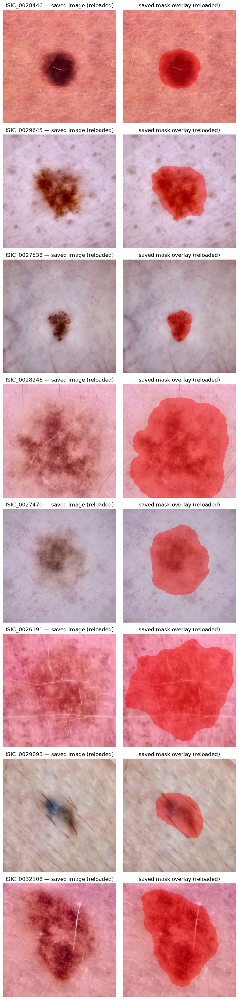


Check: does the red mask overlay still align with the visible lesion boundary
in every row, after a full save-to-disk-and-reload cycle?


In [29]:
"""
12_03_pipeline_validation.txt
Combined Single-Pass Pipeline — Output Validation (Section 12).

Validates the ACTUAL SAVED FILES on disk (not the in-memory pipeline
output) — this is the real proof Phase 4 needs, since a save/reload
cycle (JPEG compression, PNG round-trip) could in principle introduce
issues the in-memory checks never would have caught.

Checks:
  1. File count: exactly 10,015 images and 10,015 masks
  2. Binary integrity: every SAVED mask, reloaded from disk, is still
     genuinely binary (0/255 only) — confirms PNG's lossless save/reload
     didn't corrupt anything
  3. Visual alignment: a random sample of saved images + saved masks,
     reloaded from disk, overlaid to confirm the lesion boundary still
     aligns after the full save/reload round-trip

Requires 12_00-12_02 already run (full dataset pass complete).
"""

import random
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm

VALIDATION_SEED = 77  # local to this validation step only
N_VALIDATION_SAMPLES = 8

print("=" * 60)
print("COMBINED PIPELINE — OUTPUT VALIDATION — Phase 1 P2")
print("=" * 60)

# --- 1. File count check ---
image_files = list(FINAL_IMAGES_DIR.glob("*.jpg"))
mask_files = list(FINAL_MASKS_DIR.glob("*_mask.png"))

print(f"\nImages saved: {len(image_files)} (expected: 10015)")
print(f"Masks saved:  {len(mask_files)} (expected: 10015)")

if len(image_files) != 10015 or len(mask_files) != 10015:
    print("WARNING: file count mismatch — check for incomplete run or resume gaps.")
else:
    print("File counts confirmed correct.")

# --- 2. Binary integrity check on SAVED masks (full dataset) ---
print(f"\nChecking binary integrity of all {len(mask_files)} saved masks...")
non_binary = []
for mask_path in tqdm(mask_files, desc="Checking saved masks"):
    mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
    if mask is None:
        non_binary.append((mask_path.name, "FAILED TO LOAD"))
        continue
    unique_vals = np.unique(mask)
    if not np.all(np.isin(unique_vals, [0, 255])):
        non_binary.append((mask_path.name, unique_vals.tolist()[:10]))

if non_binary:
    print(f"WARNING: {len(non_binary)} saved mask(s) are not strictly binary after save/reload.")
    print(f"Sample: {non_binary[:5]}")
else:
    print("Confirmed: all saved masks remain strictly binary (0/255) after the save/reload cycle.")

# --- 3. Visual alignment check on SAVED files ---
manifest_df = pd.read_csv(MANIFEST_PATH)
random.seed(VALIDATION_SEED)
sample_ids = random.sample(manifest_df["image_id"].tolist(), N_VALIDATION_SAMPLES)

print(f"\nDisplaying {N_VALIDATION_SAMPLES} saved image/mask pairs, loaded fresh from disk...")

fig, axes = plt.subplots(N_VALIDATION_SAMPLES, 2, figsize=(8, 4 * N_VALIDATION_SAMPLES))
for i, image_id in enumerate(sample_ids):
    saved_image = cv2.imread(str(FINAL_IMAGES_DIR / f"{image_id}.jpg"))
    saved_mask = cv2.imread(str(FINAL_MASKS_DIR / f"{image_id}_mask.png"), cv2.IMREAD_GRAYSCALE)

    overlay = saved_image.copy().astype(np.float32)
    red_layer = np.zeros_like(overlay)
    red_layer[..., 2] = 255
    mask_bool = saved_mask == 255
    overlay[mask_bool] = overlay[mask_bool] * 0.6 + red_layer[mask_bool] * 0.4
    overlay = overlay.astype(np.uint8)

    axes[i, 0].imshow(cv2.cvtColor(saved_image, cv2.COLOR_BGR2RGB))
    axes[i, 0].set_title(f"{image_id} — saved image (reloaded)")
    axes[i, 1].imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
    axes[i, 1].set_title("saved mask overlay (reloaded)")
    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()

print("\nCheck: does the red mask overlay still align with the visible lesion boundary")
print("in every row, after a full save-to-disk-and-reload cycle?")
print("=" * 60)